# Průzkumná a shluková analýza nabídek Airbnb v New Yorku

**Předmět:** Základy strojového učení  
**Datový soubor:** NYC Airbnb Listings (2019)  
**Zdroj dat:** [Kaggle – Airbnb NYC Overview](https://www.kaggle.com/datasets/thedevastator/airbnbs-nyc-overview)

## 1. Úvod

### 1.1 Cíl projektu

Nabídky Airbnb v New Yorku se liší cenou, polohou, typem ubytování i způsobem, jakým je hostitelé provozují. Cílem projektu je zjistit, zda lze nabídky rozdělit do smysluplných skupin (segmentů), aniž bychom předem znali jejich zařazení. Jde tedy o učení bez učitele (*unsupervised learning*).

Projekt odpovídá na tři otázky:

1. Jak se nabídky liší podle ceny, lokality, typu ubytování, dostupnosti a hodnocení?
2. Jaké skupiny nalezne algoritmus K-Means a jaké algoritmus DBSCAN a v čem se jejich výsledky liší?
3. Jsou nalezené skupiny stabilní a lze je věcně interpretovat?

### 1.2 Logika postupu

Každý krok vychází ze zjištění předchozího kroku:

1. **EDA** ukáže, jaká data máme: zešikmené ceny, chybějící hodnoty a extrémní hodnoty.
2. **Čištění a tvorba příznaků** tyto problémy řeší, aby nezkreslily výsledek shlukování.
3. **Příprava příznaků** (logaritmická transformace, One-Hot Encoding, standardizace) je nutná proto, že K-Means i DBSCAN počítají euklidovskou vzdálenost. Ta je citlivá na rozdílná měřítka proměnných a nelze ji počítat z textových kategorií.
4. **Shluková analýza:** K-Means (počet shluků zdůvodníme metodou lokte a Silhouette Score) a DBSCAN (hustotní metoda, která navíc označí šum).
5. **Vyhodnocení a interpretace:** porovnání obou metod, ověření stability pomocí ARI a věcný popis shluků v původních jednotkách.

### 1.3 Základní předpoklady

- Jeden řádek představuje jednu nabídku Airbnb.
- Podobnost dvou nabídek je dána euklidovskou vzdáleností v prostoru vybraných příznaků.
- Identifikátory a textové sloupce (`id`, `name`, `host_id`, `host_name`, `last_review`) do shlukování nevstupují, protože nepopisují vlastnosti nabídky. Konečný výběr příznaků je v sekci 5.
- Čísla shluků jsou pouze označení. Význam shluků určíme až interpretací pomocí původních proměnných.

In [204]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

# Načtení datasetu z GitHubu
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)

print("Počet řádků a sloupců:", df.shape)
display(df.head())

Počet řádků a sloupců: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 2. Průzkumná analýza dat (EDA)

### 2.1 Základní informace o datasetu

Nejprve se podíváme na strukturu datasetu, datové typy jednotlivých proměnných a chybějící hodnoty.

Cílem je lépe porozumět datům a identifikovat možné problémy, které bude potřeba vyřešit před shlukovou analýzou.

### Popis proměnných

| Proměnná | Význam |
|---|---|
| `id`, `host_id` | identifikátor nabídky a hostitele |
| `name`, `host_name` | název nabídky a jméno hostitele (text) |
| `neighbourhood_group` | městská část (Manhattan, Brooklyn, Queens, Bronx, Staten Island) |
| `neighbourhood` | konkrétní čtvrť |
| `latitude`, `longitude` | zeměpisná poloha |
| `room_type` | typ ubytování (celý byt/dům, soukromý pokoj, sdílený pokoj) |
| `price` | cena za noc v USD |
| `minimum_nights` | minimální počet nocí na jednu rezervaci |
| `number_of_reviews` | celkový počet hodnocení |
| `last_review` | datum posledního hodnocení |
| `reviews_per_month` | průměrný počet hodnocení za měsíc |
| `calculated_host_listings_count` | počet nabídek jednoho hostitele |
| `availability_365` | počet dní v roce, kdy je nabídka dostupná |

In [145]:

# Datove typy a chybejici hodnoty
df.info()

# Popisna statistika
display(df.describe(include="all").T)

# Pocet chybejicich hodnot
display(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,48895.0,NaN,NaN,NaN,19017143.23618,10983108.38561,2539.0,9471945.0,19677284.0,29152178.5,36487245.0
name,48879,47905,Hillside Hotel,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,48895.0,NaN,NaN,NaN,67620010.64661,78610967.032667,2438.0,7822033.0,30793816.0,107434423.0,274321313.0
host_name,48874,11452,Michael,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_group,48895,5,Manhattan,21661,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood,48895,221,Williamsburg,3920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,48895.0,NaN,NaN,NaN,40.728949,0.05453,40.49979,40.6901,40.72307,40.763115,40.91306
longitude,48895.0,NaN,NaN,NaN,-73.95217,0.046157,-74.24442,-73.98307,-73.95568,-73.936275,-73.71299
room_type,48895,3,Entire home/apt,25409,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,48895.0,NaN,NaN,NaN,152.720687,240.15417,0.0,69.0,106.0,175.0,10000.0


id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

### První pozorování

Dataset obsahuje 48 895 nabídek Airbnb a 16 proměnných.

Základní statistická analýza ukázala několik zajímavých skutečností:

- Průměrná cena ubytování je přibližně 153 USD, zatímco medián je 106 USD. To naznačuje pravostranně zešikmené rozdělení cen.
- Ceny se pohybují od 0 do 10 000 USD. Extrémní hodnoty bude potřeba dále prozkoumat.
- Maximální požadovaná délka pobytu dosahuje 1 250 nocí, což může představovat odlehlou hodnotu.
- Proměnné `last_review` a `reviews_per_month` obsahují každá 10 052 chybějících hodnot.

Tato zjištění využijeme při další analýze rozdělení cen a následném čištění dat.

### 2.2 Rozdělení cen ubytování

Nejprve prozkoumáme rozdělení cen za noc. Pomocí histogramů zjistíme, v jakém cenovém rozmezí se nachází většina nabídek a zda dataset obsahuje extrémně vysoké ceny.

Pro lepší přehlednost zobrazíme nejprve všechny ceny a následně pouze nabídky s cenou do 500 USD.

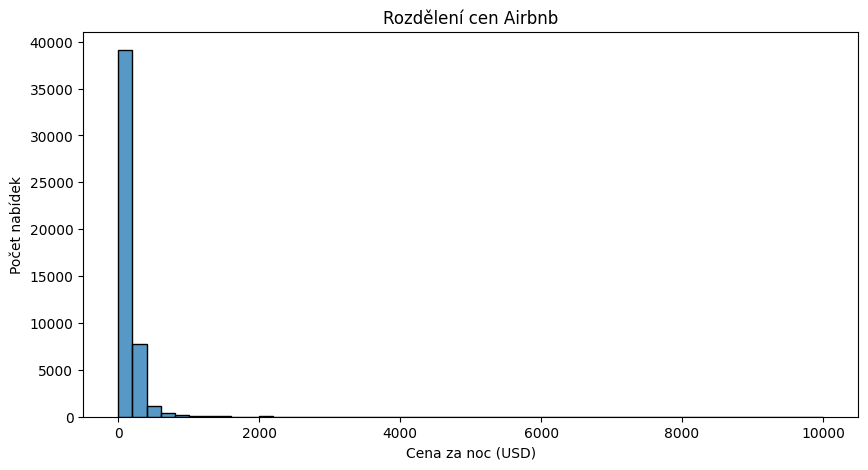

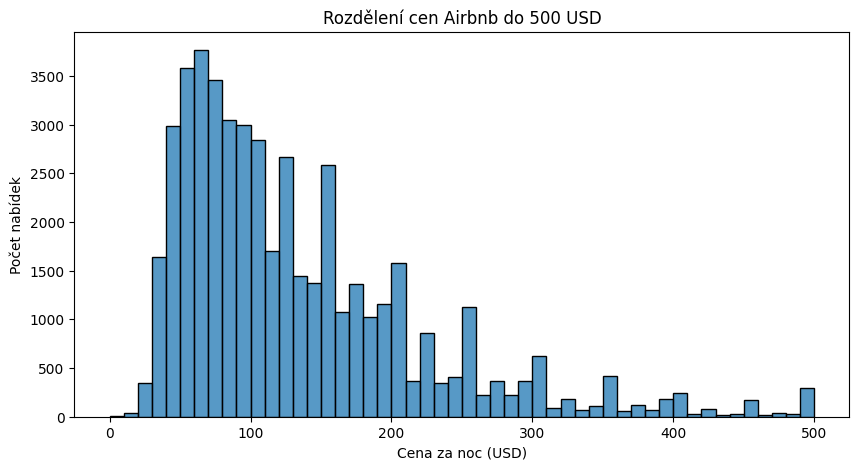

In [146]:

# Rozdeleni vsech cen
plt.figure(figsize=(10, 5))
sns.histplot(df["price"], bins=50)
plt.title("Rozdělení cen Airbnb")
plt.xlabel("Cena za noc (USD)")
plt.ylabel("Počet nabídek")
plt.show()

# Detail cen do 500 USD
plt.figure(figsize=(10, 5))
sns.histplot(df[df["price"] <= 500]["price"], bins=50)
plt.title("Rozdělení cen Airbnb do 500 USD")
plt.xlabel("Cena za noc (USD)")
plt.ylabel("Počet nabídek")
plt.show()


**Interpretace:**

Rozdělení cen je výrazně pravostranně zešikmené. Většina nabídek se nachází v nižších cenových kategoriích, zatímco malý počet nabídek dosahuje velmi vysokých cen až 10 000 USD.

Tyto extrémní hodnoty ztěžují čitelnost prvního histogramu. Druhý histogram proto zobrazuje pouze ceny do 500 USD, což umožňuje lépe pozorovat rozdělení běžnějších cen.

Omezení na 500 USD slouží pouze k vizualizaci, původní data zatím neměníme.

V další části se zaměříme na geografické rozložení nabídek a porovnáme ceny mezi jednotlivými částmi New Yorku.

### 2.3 Rozložení nabídek podle městských částí

Nejprve zjistíme, jak jsou nabídky Airbnb rozděleny mezi pět městských částí New Yorku. Následně porovnáme ceny ubytování, abychom zjistili, zda lokalita souvisí s cenou.

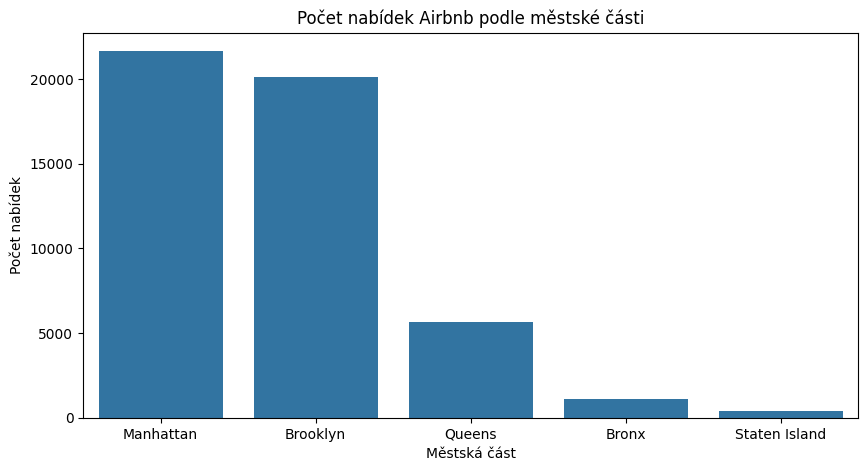

In [147]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="neighbourhood_group",
    order=df["neighbourhood_group"].value_counts().index
)

plt.title("Počet nabídek Airbnb podle městské části")
plt.xlabel("Městská část")
plt.ylabel("Počet nabídek")
plt.show()


**Interpretace:**

Nejvíce nabídek Airbnb se nachází na Manhattanu a v Brooklynu. Následuje Queens, zatímco Bronx a Staten Island mají výrazně méně nabídek.

Nabídky tedy nejsou mezi městskými částmi rozloženy rovnoměrně. Dále ověříme, zda se tyto oblasti liší také cenami ubytování.

neighbourhood_group
Manhattan        150.0
Brooklyn          90.0
Queens            75.0
Staten Island     75.0
Bronx             65.0
Name: price, dtype: float64

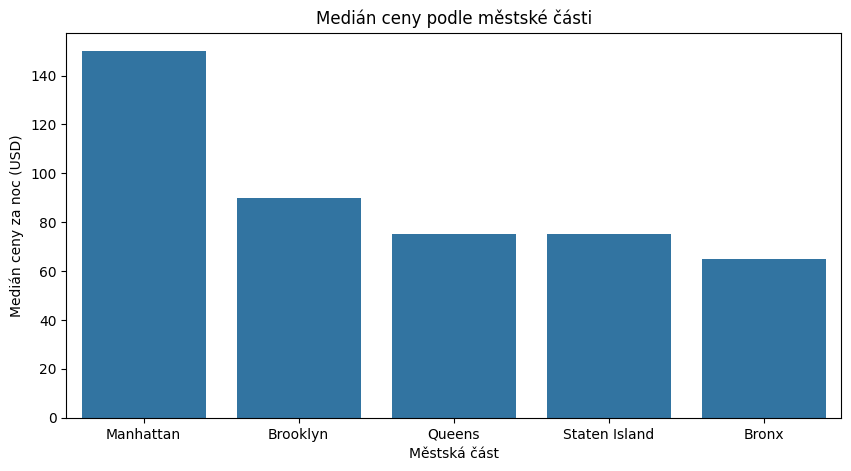

In [148]:

# Median ceny podle mestske casti
median_prices = df.groupby("neighbourhood_group")["price"].median()
median_prices = median_prices.sort_values(ascending=False)

display(median_prices)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=median_prices.index,
    y=median_prices.values
)

plt.title("Medián ceny podle městské části")
plt.xlabel("Městská část")
plt.ylabel("Medián ceny za noc (USD)")
plt.show()


**Interpretace:**

Nejvyšší medián ceny za noc má Manhattan (150 USD), následuje Brooklyn (90 USD), Queens a Staten Island (75 USD) a Bronx (65 USD).

Výsledky naznačují, že lokalita souvisí s cenou ubytování. Samotný medián však neukazuje rozptýlení cen, proto se dále podíváme na jejich rozdělení pomocí krabicového grafu (boxplotu).

### 2.4 Porovnání rozdělení cen pomocí boxplotu

Pro podrobnější porovnání cen mezi městskými částmi použijeme boxplot, který zobrazuje medián, kvartily a rozptýlení hodnot.

Pro lepší čitelnost nebudeme zobrazovat odlehlé body. Tyto hodnoty však z datasetu neodstraňujeme.

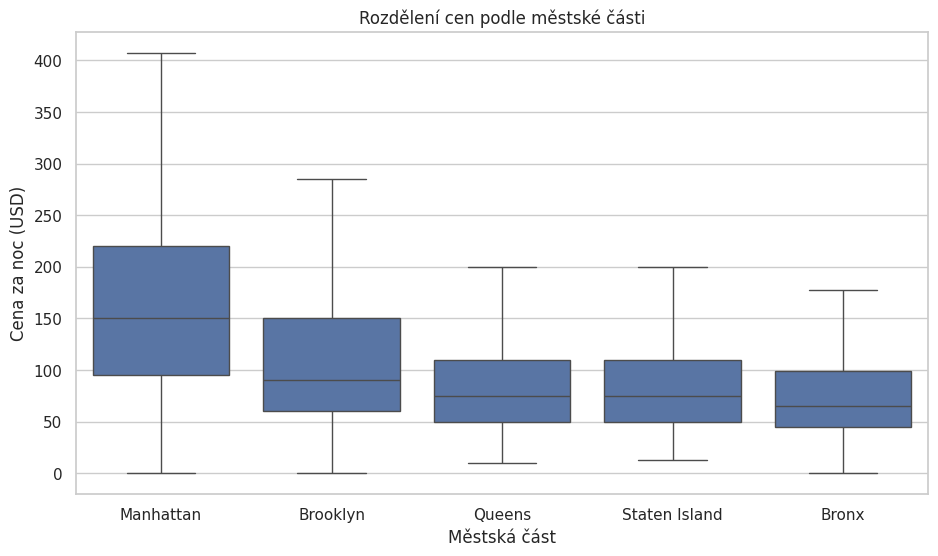

In [216]:

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="neighbourhood_group",
    y="price",
    order=median_prices.index,
    showfliers=False
)

plt.title("Rozdělení cen podle městské části")
plt.xlabel("Městská část")
plt.ylabel("Cena za noc (USD)")
plt.show()


**Interpretace:**

Manhattan vykazuje nejvyšší medián ceny a zároveň větší variabilitu cen než většina ostatních městských částí.

Boxplot potvrzuje, že ceny se mezi jednotlivými oblastmi liší. Tyto rozdíly však nemusí být způsobeny pouze lokalitou, ale také typem nabízeného ubytování.

V další části proto prozkoumáme jednotlivé typy ubytování a jejich ceny.

### 2.5 Rozdělení nabídek podle typu ubytování

Kromě lokality může cenu ovlivňovat také typ ubytování. Nejprve zjistíme, jaké typy ubytování se v datasetu vyskytují nejčastěji, a následně porovnáme jejich mediánové ceny.

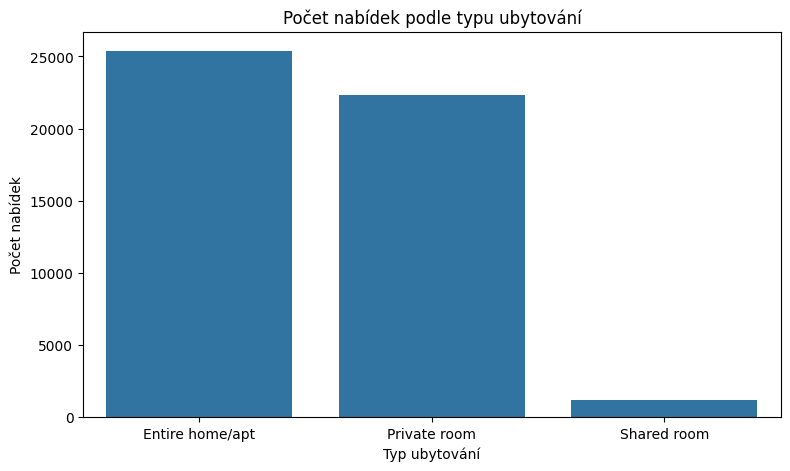

room_type
Entire home/apt    160.0
Private room        70.0
Shared room         45.0
Name: price, dtype: float64

In [150]:

# Pocet nabidek podle typu ubytovani
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="room_type",
    order=df["room_type"].value_counts().index
)

plt.title("Počet nabídek podle typu ubytování")
plt.xlabel("Typ ubytování")
plt.ylabel("Počet nabídek")
plt.show()

# Median ceny podle typu ubytovani
room_prices = df.groupby("room_type")["price"].median()
display(room_prices.sort_values(ascending=False))


**Interpretace:**

Nejčastějšími typy ubytování jsou celé byty nebo domy (*Entire home/apt*) a soukromé pokoje (*Private room*). Sdílené pokoje (*Shared room*) tvoří pouze malou část nabídek.

Medián ceny za noc se mezi jednotlivými typy výrazně liší:

- Entire home/apt: 160 USD
- Private room: 70 USD
- Shared room: 45 USD

Výsledky ukazují, že cena ubytování souvisí nejen s lokalitou, ale také s typem ubytování.

Při následné shlukové analýze proto budeme zohledňovat oba tyto příznaky.

### 2.6 Analýza numerických proměnných

V této části analyzujeme tři numerické proměnné: `minimum_nights`, `number_of_reviews` a `availability_365`.

Zaměříme se na jejich rozdělení a extrémní hodnoty, které mohou ovlivnit následné shlukování.

In [151]:

columns = ["minimum_nights", "number_of_reviews", "availability_365"]

display(df[columns].describe().T)


,count,mean,std,min,25%,50%,75%,max
minimum_nights,48895.0,7.029962,20.510550,1.0,1.0,3.0,5.0,1250.0
number_of_reviews,48895.0,23.274466,44.550582,0.0,1.0,5.0,24.0,629.0
availability_365,48895.0,112.781327,131.622289,0.0,0.0,45.0,227.0,365.0


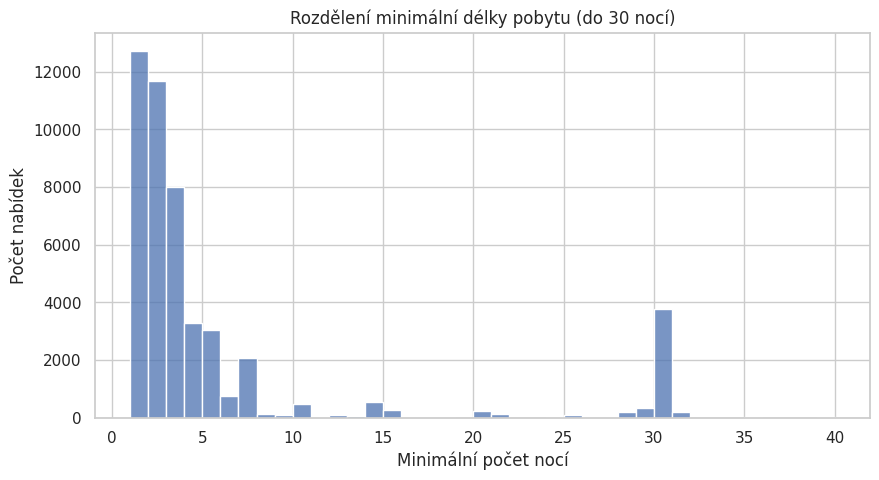

In [218]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["minimum_nights"] <= 40],
    x="minimum_nights",
    binwidth=1
)

plt.title("Rozdělení minimální délky pobytu (do 30 nocí)")
plt.xlabel("Minimální počet nocí")
plt.ylabel("Počet nabídek")
plt.show()


**Interpretace:**

Většina nabídek vyžaduje minimální pobyt v délce 1 až 3 nocí. Výraznější zastoupení mají také nabídky s minimální délkou pobytu 30 nocí.

Rozdělení je pravostranně zešikmené a maximální hodnota dosahuje 1 250 nocí. Pro lepší přehlednost graf zobrazuje pouze hodnoty do 30 nocí, ostatní záznamy však zůstávají v datasetu.

In [153]:
print(df["minimum_nights"].value_counts().head(15))

minimum_nights
1     12720
2     11696
3      7999
30     3760
4      3303
5      3034
7      2058
6       752
14      562
10      483
29      340
15      279
20      223
28      203
31      201
Name: count, dtype: int64


Výpis nejčastějších hodnot potvrzuje, že většina nabídek vyžaduje 1 až 3 noci. Výrazný vrchol je také u hodnoty 30 nocí, která odpovídá měsíčním pronájmům. Přesný počet těchto nabídek uvádíme v sekci 3.5. Další pozorování se tedy týká dvou odlišných typů nabídek: krátkodobého turistického ubytování a dlouhodobých pronájmů.

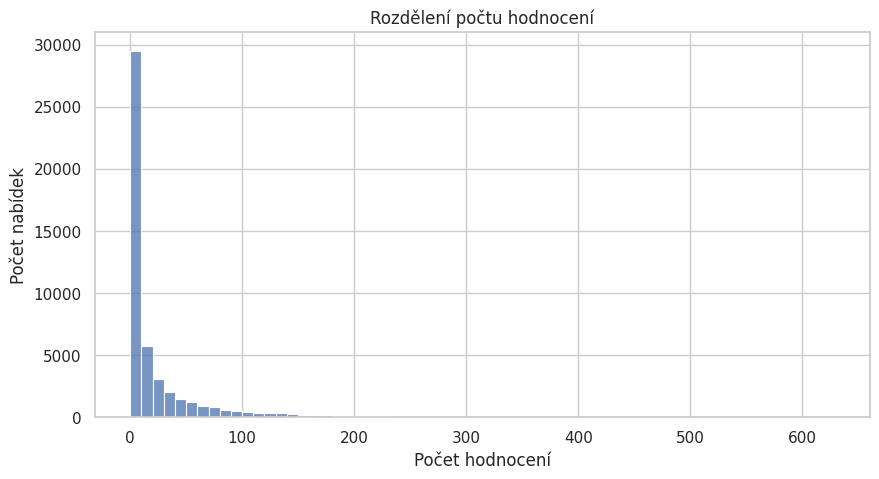

In [205]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="number_of_reviews",
    binwidth=10
)

plt.title("Rozdělení počtu hodnocení")
plt.xlabel("Počet hodnocení")
plt.ylabel("Počet nabídek")
plt.show()

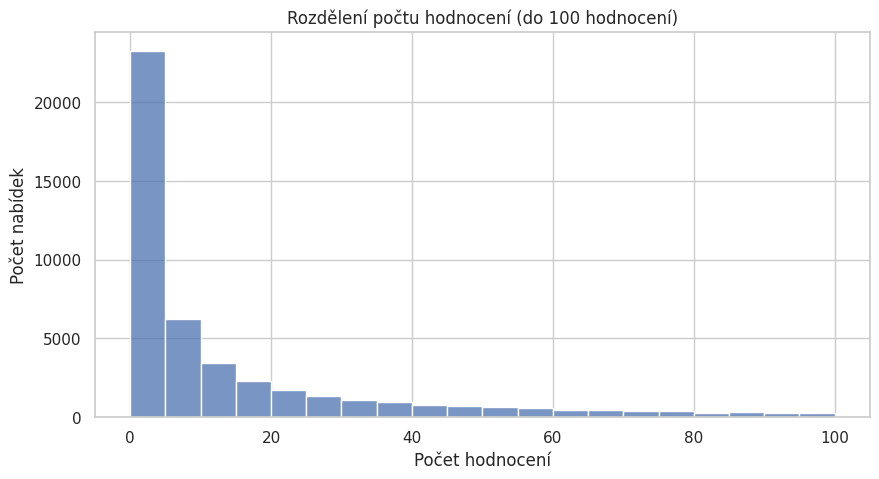

In [206]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["number_of_reviews"] <= 100],
    x="number_of_reviews",
    binwidth=5
)

plt.title("Rozdělení počtu hodnocení (do 100 hodnocení)")
plt.xlabel("Počet hodnocení")
plt.ylabel("Počet nabídek")
plt.show()

In [207]:
print("Nabídky bez hodnocení:", (df["number_of_reviews"] == 0).sum())
print("Nabídky s hodnocením:", (df["number_of_reviews"] > 0).sum())

Nabídky bez hodnocení: 10052
Nabídky s hodnocením: 38843


**Interpretace:**

Většina nabídek má relativně malý počet hodnocení. Rozdělení je výrazně pravostranně zešikmené.

Celkem 10 052 nabídek nemá žádné hodnocení, což představuje přibližně 20,6 % datasetu.

Proto dále ověříme, zda absence hodnocení souvisí s chybějícími hodnotami v proměnných `last_review` a `reviews_per_month`.

In [157]:

no_reviews = df["number_of_reviews"] == 0

print("Nabidky bez hodnoceni:", no_reviews.sum())
print("Chybejici last_review:",
      df.loc[no_reviews, "last_review"].isna().sum())
print("Chybejici reviews_per_month:",
      df.loc[no_reviews, "reviews_per_month"].isna().sum())
print("Chybejici reviews_per_month u hodnocenych nabidek:",
      df.loc[~no_reviews, "reviews_per_month"].isna().sum())


Nabidky bez hodnoceni: 10052
Chybejici last_review: 10052
Chybejici reviews_per_month: 10052
Chybejici reviews_per_month u hodnocenych nabidek: 0


**Interpretace:**

Ověření ukázalo, že všech 10 052 nabídek bez hodnocení má chybějící hodnoty v proměnných `last_review` a `reviews_per_month`.

U nabídek s alespoň jedním hodnocením chybějící hodnoty `reviews_per_month` nebyly nalezeny.

Chybějící hodnoty tedy souvisejí s absencí hodnocení. Tuto informaci využijeme při čištění dat.

### Dostupnost ubytování během roku

Proměnná `availability_365` udává počet dní, kdy je ubytování dostupné k rezervaci v rámci 365denního období.

Pomocí histogramu prozkoumáme rozdělení této proměnné a zjistíme, kolik nabídek má nulovou nebo celoroční dostupnost.

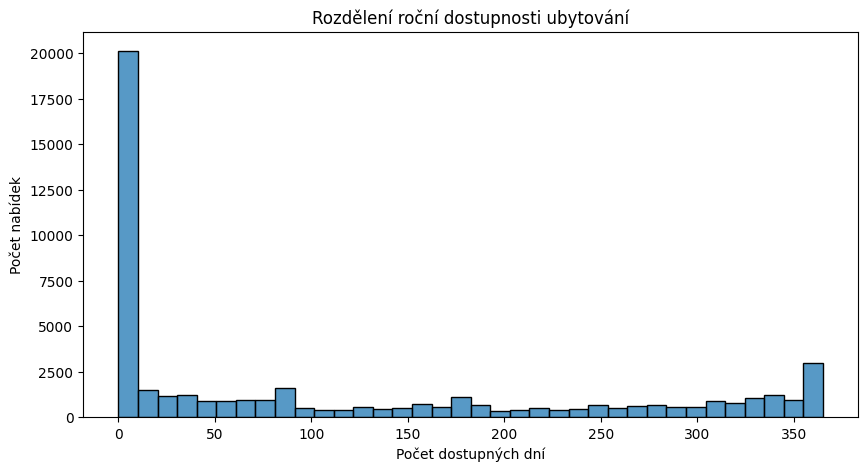

Nulova dostupnost: 17533
Celorocni dostupnost: 1295


In [158]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="availability_365",
    binwidth=10
)

plt.title("Rozdělení roční dostupnosti ubytování")
plt.xlabel("Počet dostupných dní")
plt.ylabel("Počet nabídek")
plt.show()

# Kontrola krajnich hodnot
print("Nulova dostupnost:", (df["availability_365"] == 0).sum())
print("Celorocni dostupnost:", (df["availability_365"] == 365).sum())


**Interpretace:**

Rozdělení roční dostupnosti ukazuje výraznou koncentraci nabídek s nulovou dostupností a další koncentraci poblíž 365 dní.

- **17 533 nabídek (35,9 %)** má nulovou dostupnost.
- **1 295 nabídek (2,6 %)** je dostupných po celý rok.

Nulová dostupnost nemusí nutně znamenat, že je ubytování plně rezervované. Může souviset také s omezením kalendáře nebo neaktivní nabídkou.

Proměnná `availability_365` tak může být užitečná při následné shlukové analýze, protože umožňuje rozlišovat nabídky podle jejich dostupnosti.

### Počet nabídek na hostitele

Proměnná `calculated_host_listings_count` udává, kolik nabídek má stejný hostitel. Do shlukování vstupuje, proto ji prozkoumáme již nyní.

count    48895.000000
mean         7.143982
std         32.952519
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        327.000000
Name: calculated_host_listings_count, dtype: float64
Nabídky hostitelů s více než 10 nabídkami: 2967


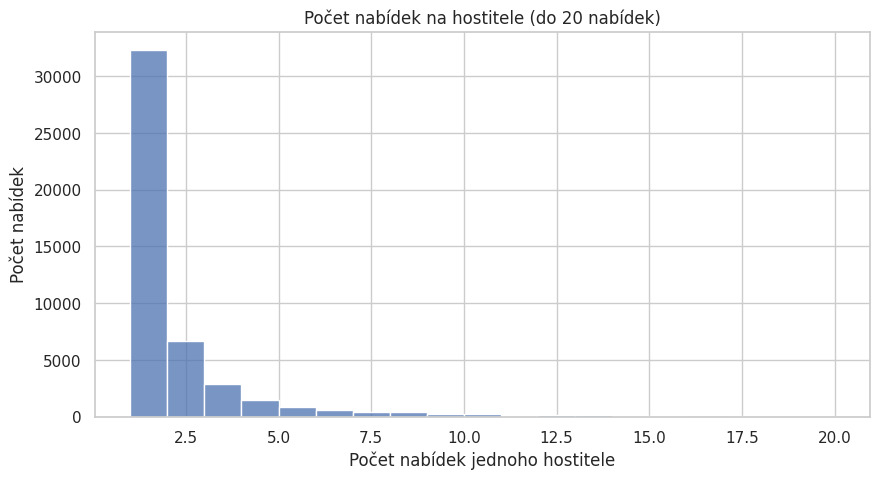

In [208]:
print(df["calculated_host_listings_count"].describe())
print("Nabídky hostitelů s více než 10 nabídkami:",
      (df["calculated_host_listings_count"] > 10).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["calculated_host_listings_count"] <= 20],
    x="calculated_host_listings_count",
    binwidth=1
)

plt.title("Počet nabídek na hostitele (do 20 nabídek)")
plt.xlabel("Počet nabídek jednoho hostitele")
plt.ylabel("Počet nabídek")
plt.show()



**Interpretace:**

Většina nabídek patří hostitelům s jednou nebo několika málo nabídkami (medián: *1.00*). Rozdělení je výrazně pravostranně zešikmené a maximální hodnota dosahuje *327.00* nabídek na hostitele.

Z hlediska domény lze rozlišit dva typy hostitelů: soukromé osoby, které pronajímají jednu nemovitost, a profesionální provozovatele s desítkami nabídek. Tento rozdíl může být důležitým rozlišovacím znakem při shlukování. Protože je rozdělení zešikmené, použijeme při přípravě příznaků logaritmickou transformaci.

### 2.7 Korelační analýza

Pomocí korelační matice prozkoumáme lineární vztahy mezi numerickými proměnnými.

Cílem je zjistit, které proměnné spolu souvisejí a zda některé z nich neposkytují podobné informace.

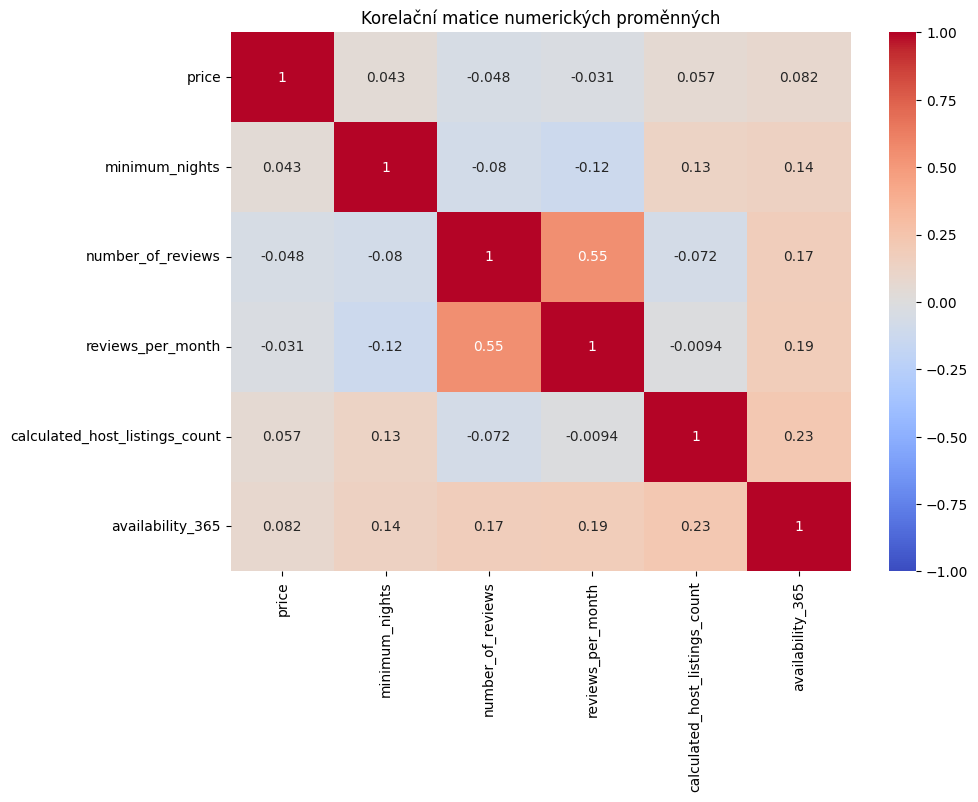

In [159]:

numeric_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Korelační matice numerických proměnných")
plt.show()


**Interpretace:**

Korelační matice ukazuje, že většina numerických proměnných má mezi sebou slabé lineární vztahy.

Nejsilnější kladná korelace byla zjištěna mezi `number_of_reviews` a `reviews_per_month` (r = 0,55).

Slabší kladná korelace existuje mezi `calculated_host_listings_count` a `availability_365` (r = 0,23).

Cena vykazuje velmi slabé lineární korelace s ostatními sledovanými numerickými proměnnými.

Výsledky naznačují, že jednotlivé charakteristiky nabídek zachycují různé aspekty ubytování, což je důležité pro následnou shlukovou analýzu.

Slabé korelace ceny je třeba číst opatrně. Pearsonův koeficient měří pouze lineární vztah a je citlivý na extrémní hodnoty, které cenové rozdělení obsahuje. Slabá korelace proto neznamená, že cena nesouvisí s ostatními charakteristikami. Cenu lépe vysvětlují kategoriální proměnné, tedy lokalita a typ ubytování (sekce 2.3 až 2.5 a 2.9), které se v korelační matici neobjevují.

### 2.8 Geografické rozložení nabídek Airbnb

Pomocí zeměpisné šířky a délky zobrazíme prostorové rozložení nabídek Airbnb v New Yorku.

Cílem je zjistit, ve kterých oblastech se nabídky nejvíce koncentrují a jak se jejich rozložení liší mezi městskými částmi.

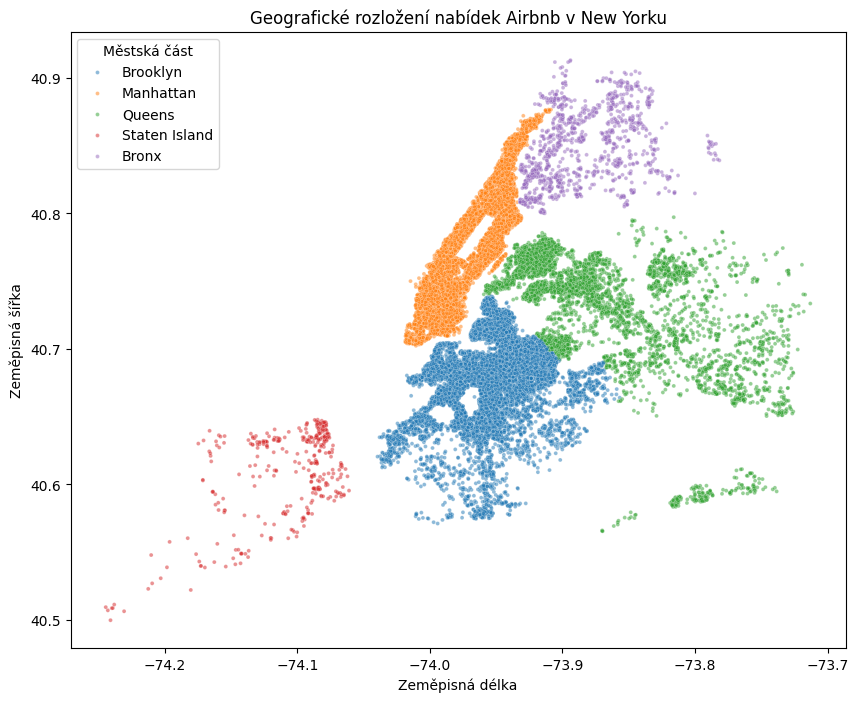

In [160]:

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    hue="neighbourhood_group",
    s=8,
    alpha=0.5
)

plt.title("Geografické rozložení nabídek Airbnb v New Yorku")
plt.xlabel("Zeměpisná délka")
plt.ylabel("Zeměpisná šířka")
plt.legend(title="Městská část")
plt.show()


**Interpretace:**

Nabídky Airbnb jsou nejvíce koncentrovány na Manhattanu a v některých částech Brooklynu. Queens vykazuje rozptýlenější geografické rozložení, zatímco Bronx a Staten Island mají výrazně méně nabídek.

Výsledky odpovídají předchozí analýze počtu nabídek podle městských částí.

Geografická poloha může být důležitým příznakem při shlukování, protože umožňuje rozlišovat nabídky podle jejich umístění.

### 2.9 Porovnání cen podle městské části a typu ubytování

V předchozích analýzách jsme zjistili, že cena souvisí s lokalitou i typem ubytování.

Nyní oba příznaky porovnáme současně pomocí mediánových cen a teplotní mapy.

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.0,53.5,40.0
Brooklyn,145.0,65.0,36.0
Manhattan,191.0,90.0,69.0
Queens,120.0,60.0,37.0
Staten Island,100.0,50.0,30.0


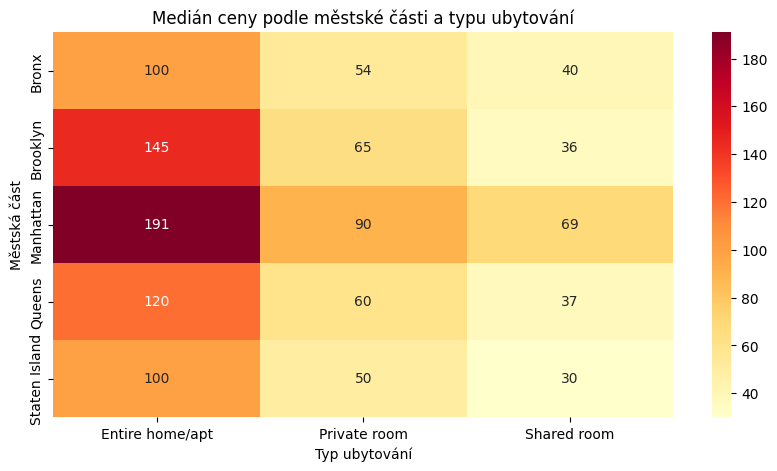

In [161]:

# Median ceny podle mestske casti a typu ubytovani
price_comparison = df.pivot_table(
    values="price",
    index="neighbourhood_group",
    columns="room_type",
    aggfunc="median"
)

display(price_comparison)

plt.figure(figsize=(10, 5))

sns.heatmap(
    price_comparison,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Medián ceny podle městské části a typu ubytování")
plt.xlabel("Typ ubytování")
plt.ylabel("Městská část")
plt.show()


**Interpretace:**

Mediánové ceny se liší podle městské části i typu ubytování.

Celé byty a domy (*Entire home/apt*) mají ve všech pěti městských částech nejvyšší mediánové ceny, zatímco sdílené pokoje (*Shared room*) patří mezi nejlevnější možnosti.

Nejvyšší ceny byly zaznamenány na Manhattanu. Například medián ceny celého bytu nebo domu zde dosahuje 191 USD, zatímco v Bronxu a na Staten Islandu činí 100 USD.

Výsledky potvrzují, že lokalita i typ ubytování jsou relevantní charakteristiky pro další analýzu.

### 2.10 Shrnutí EDA a rozhodnutí pro další kroky

Průzkumná analýza odhalila několik zjištění, ze kterých přímo vycházejí následující kroky projektu:

| Zjištění v EDA | Důsledek pro další postup |
|---|---|
| Cena je výrazně pravostranně zešikmená a obsahuje nulové i extrémní hodnoty | Kontrola neplatných cen a odlehlých hodnot (sekce 3.2, 3.3), logaritmická transformace (3.4) |
| Chybějící `reviews_per_month` a `last_review` se vyskytují právě u nabídek bez hodnocení | Chybějící hodnoty nejsou náhodné, `reviews_per_month` doplníme nulou (3.1) |
| `minimum_nights` má vrchol u 30 nocí a hodnoty až 1 250 | Kontrola dlouhých pobytů (3.5), logaritmická transformace, kategorie délky pobytu (4.2) |
| Třetina nabídek má nulovou dostupnost, což může znamenat obsazenost i neaktivní nabídku | Dostupnost převedeme na podíl v roce (4.1) a při interpretaci shluků zohledníme nejednoznačný význam nuly |
| Cena závisí na městské části i typu ubytování, ale uvnitř skupin se výrazně liší | Příznak relativní ceny vůči podobným nabídkám (4.4) |
| Korelace mezi numerickými proměnnými jsou slabé (nejsilnější r = 0,55) | Proměnné poskytují převážně odlišnou informaci, proto je do shlukování vybereme společně |
| Počet nabídek na hostitele je zešikmený | Logaritmická transformace (5.3) |
| Poloha je zachycena městskou částí | Jako příznak použijeme `neighbourhood_group` (5.1) |

## 3. Čištění a předzpracování dat

Průzkumná analýza (sekce 2.10) ukázala čtyři problémy, které by mohly zkreslit shlukování: chybějící hodnoty, nulové ceny, extrémní ceny a neobvykle dlouhé minimální pobyty. Algoritmy K-Means a DBSCAN pracují se vzdálenostmi, takže i malý počet extrémních hodnot může výrazně posunout výsledek.

U každého problému proto nejdříve ověříme, zda jde o chybu, nebo o skutečný jev, a teprve podle toho se rozhodneme. Žádný záznam neodstraňujeme jen proto, že je neobvyklý.

In [162]:

# Kontrola duplicit
print("Duplicitni radky:", df.duplicated().sum())
print("Duplicitni ID:", df["id"].duplicated().sum())


Duplicitni radky: 0
Duplicitni ID: 0


**Interpretace:**

V datasetu nebyly nalezeny duplicitní řádky ani duplicitní identifikátory nabídek. Z tohoto důvodu není nutné žádné záznamy odstraňovat.

### 3.1 Chybějící hodnoty

V EDA jsme zjistili, že všech 10 052 nabídek bez hodnocení má chybějící `last_review` i `reviews_per_month`. Chybějící hodnoty tedy nejsou náhodné, ale vyplývají z toho, že nabídka dosud nemá žádné hodnocení.

Proto nepoužijeme průměr ani medián. Průměr by nabídkám bez hodnocení uměle přisoudil nenulovou frekvenci hodnocení, která ve skutečnosti neexistuje. Správnou hodnotou je **0**, protože nabídka bez hodnocení má nulový průměrný počet hodnocení za měsíc.

In [163]:

# Prehled chybejicich hodnot
missing = pd.DataFrame({
    "Pocet": df.isna().sum(),
    "Procenta": (df.isna().mean() * 100).round(2)
})

display(missing[missing["Pocet"] > 0])

# Vytvoreni kopie datasetu
df_clean = df.copy()

# Nahrazeni chybejicich hodnot
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)

print("Chybejici reviews_per_month:",
      df_clean["reviews_per_month"].isna().sum())


,Pocet,Procenta
name,16,0.03
host_name,21,0.04
last_review,10052,20.56
reviews_per_month,10052,20.56


Chybejici reviews_per_month: 0


**Interpretace:**

Chybějící hodnoty v `reviews_per_month` byly nahrazeny nulou, protože odpovídají nabídkám bez hodnocení. Informace o tom, zda nabídka hodnocení má, zachováme také v samostatném příznaku `has_reviews` (sekce 4.3).

Sloupce `name` a `host_name` obsahují jen několik chybějících hodnot (16 a 21) a sloupec `last_review` do shlukování nevstupuje. Tyto hodnoty proto neřešíme, protože by jejich doplnění nemělo na výsledek žádný vliv.

### 3.2 Kontrola neplatných cen

Před dalším zpracováním zkontrolujeme nulové a záporné ceny. Jelikož analyzujeme placené ubytování, nabídky s nulovou cenou nebudeme zahrnovat do shlukové analýzy.

In [209]:
# Kontrola cen
print("Minimální cena:", df_clean["price"].min())
print("Maximální cena:", df_clean["price"].max())
print("Nulové ceny:", (df_clean["price"] == 0).sum())
print("Záporné ceny:", (df_clean["price"] < 0).sum())

# Odstranění neplatných cen
print("Počet záznamů před čištěním:", len(df_clean))
df_clean = df_clean[df_clean["price"] > 0].copy()

print("Počet záznamů po vyčištění:", len(df_clean))


Minimální cena: 10
Maximální cena: 10000
Nulové ceny: 0
Záporné ceny: 0
Počet záznamů před čištěním: 48884
Počet záznamů po vyčištění: 48884


**Interpretace:**

V datasetu bylo nalezeno 11 nabídek s nulovou cenou a žádná nabídka se zápornou cenou.

Nulové ceny byly z analýzy odstraněny, protože neodpovídají zaměření projektu na placené ubytování a mohly by ovlivnit výsledky shlukování.

Po odstranění těchto záznamů obsahuje dataset **48 884 nabídek**.

Nulová cena nedává u placeného ubytování smysl. Jde o zanedbatelný podíl (11 z 48 895 nabídek, tedy přibližně 0,02 %), proto jejich odstranění výsledky neovlivní. Další hodnoty, které působí neobvykle, zatím neodstraňujeme.

### 3.3 Analýza odlehlých hodnot

V předchozí analýze jsme zjistili, že rozdělení cen je výrazně pravostranně zešikmené a obsahuje extrémní hodnoty.

Pro identifikaci potenciálně odlehlých hodnot použijeme mezikvartilové rozpětí (IQR). Cílem je zjistit, kolik nabídek se výrazně odlišuje od běžného cenového rozmezí, a rozhodnout o jejich dalším zpracování.

In [165]:

# Vypocet IQR
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identifikace odlehlych hodnot
outliers = df_clean[
    (df_clean["price"] < lower_bound) |
    (df_clean["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Dolni hranice:", lower_bound)
print("Horni hranice:", upper_bound)
print("Pocet odlehlych hodnot:", len(outliers))
print("Podil odlehlych hodnot:", round(len(outliers) / len(df_clean) * 100, 2), "%")


Q1: 69.0
Q3: 175.0
IQR: 106.0
Dolni hranice: -90.0
Horni hranice: 334.0
Pocet odlehlych hodnot: 2972
Podil odlehlych hodnot: 6.08 %


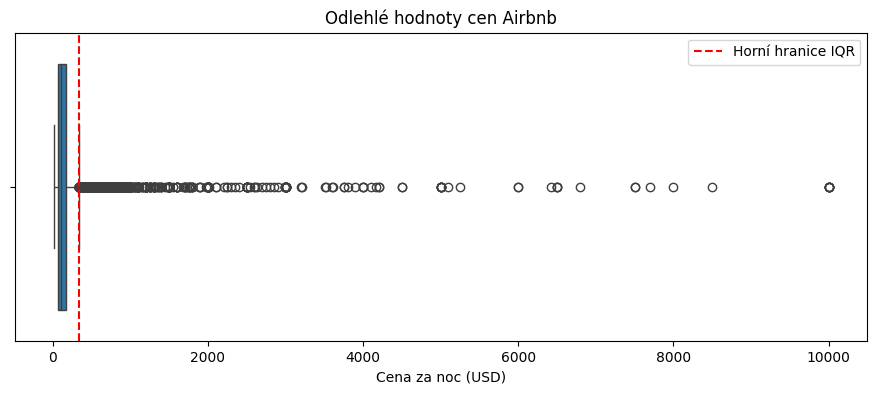

In [166]:

plt.figure(figsize=(11, 4))

sns.boxplot(data=df_clean, x="price")

plt.axvline(
    upper_bound,
    color="red",
    linestyle="--",
    label="Horní hranice IQR"
)

plt.title("Odlehlé hodnoty cen Airbnb")
plt.xlabel("Cena za noc (USD)")
plt.legend()
plt.show()


**Interpretace:**

Pomocí metody IQR byla stanovena horní hranice odlehlých hodnot na 334 USD. Tuto hranici překračuje 2 972 nabídek, což představuje přibližně 6,08 % datasetu.

Tyto hodnoty však nemusí být chybné. Vysoké ceny mohou souviset například s luxusním ubytováním, většími nemovitostmi nebo atraktivní lokalitou.

Proto odlehlé hodnoty automaticky neodstraníme, ale nejprve prozkoumáme několik extrémních případů.

In [167]:

# Odlehle hodnoty podle typu ubytovani
expensive_listings = df_clean[df_clean["price"] > upper_bound]

print("Pocet odlehlych hodnot podle typu ubytovani:")
print(expensive_listings["room_type"].value_counts())

print("\nPodil odlehlych hodnot v jednotlivych typech ubytovani (%):")
print(
    (df_clean["price"] > upper_bound)
    .groupby(df_clean["room_type"])
    .mean()
    .mul(100)
    .round(2)
)


Pocet odlehlych hodnot podle typu ubytovani:
room_type
Entire home/apt    2620
Private room        330
Shared room          22
Name: count, dtype: int64

Podil odlehlych hodnot v jednotlivych typech ubytovani (%):
room_type
Entire home/apt    10.31
Private room        1.48
Shared room         1.90
Name: price, dtype: float64


**Interpretace:**

Nejvyšší podíl cenových odlehlých hodnot mají celé byty a domy (10,31 %), zatímco u soukromých a sdílených pokojů je tento podíl výrazně nižší.

To naznačuje, že vysoké ceny mohou souviset s typem ubytování. Proto nebudeme všechny odlehlé hodnoty automaticky odstraňovat.

In [168]:
# Deset nejdrazsich nabidek
display(
    df_clean.nlargest(10, "price")[
        ["neighbourhood_group", "neighbourhood",
         "room_type", "price", "minimum_nights",
         "number_of_reviews"]
    ]
)


,neighbourhood_group,neighbourhood,room_type,price,minimum_nights,number_of_reviews
9151,Queens,Astoria,Private room,10000,100,2
17692,Brooklyn,Greenpoint,Entire home/apt,10000,5,5
29238,Manhattan,Upper West Side,Entire home/apt,10000,30,0
6530,Manhattan,East Harlem,Entire home/apt,9999,5,1
12342,Manhattan,Lower East Side,Private room,9999,99,6
40433,Manhattan,Lower East Side,Entire home/apt,9999,30,0
30268,Manhattan,Tribeca,Entire home/apt,8500,30,2
4377,Brooklyn,Clinton Hill,Entire home/apt,8000,1,1
29662,Manhattan,Upper East Side,Entire home/apt,7703,1,0
42523,Manhattan,Battery Park City,Entire home/apt,7500,1,0


### Kontrola extrémních cen

Mezi deseti nejdražšími nabídkami se nacházejí ubytování s cenami od 7 500 do 10 000 USD za noc, včetně soukromých pokojů.

Některé nabídky mají také neobvykle vysoký požadovaný minimální počet nocí.

Tyto hodnoty mohou být chybné, ale bez dalších informací to nelze potvrdit. Proto porovnáme jednu z extrémních nabídek s podobným ubytováním ve stejné lokalitě.

In [169]:

# Porovnani soukromych pokoju v Astorii
astoria_rooms = df_clean[
    (df_clean["neighbourhood"] == "Astoria") &
    (df_clean["room_type"] == "Private room")
]

print("Pocet soukromych pokoju:", len(astoria_rooms))
print("Median ceny:", astoria_rooms["price"].median())
print("95. percentil:", astoria_rooms["price"].quantile(0.95))
print("Maximalni cena:", astoria_rooms["price"].max())


Pocet soukromych pokoju: 494
Median ceny: 65.0
95. percentil: 120.0
Maximalni cena: 10000


### Vyhodnocení extrémních cen

Pro podrobnější kontrolu jsme porovnali ceny soukromých pokojů v Astorii.

Z celkem 494 nabídek činí medián ceny 65 USD a 95. percentil 120 USD. Maximální cena však dosahuje 10 000 USD.

Takto vysoká cena je ve srovnání s podobnými nabídkami velmi neobvyklá. Samotná odlehlost však neznamená, že je údaj chybný.

**Rozhodnutí:** Odlehlé hodnoty ponecháme v datasetu. Pro omezení vlivu extrémních hodnot při shlukování využijeme logaritmickou transformaci.

### 3.4 Logaritmická transformace ceny

Protože rozdělení cen obsahuje extrémně vysoké hodnoty, použijeme logaritmickou transformaci `log1p()`, která počítá přirozený logaritmus z hodnoty zvýšené o 1.

Transformace zmenšuje rozdíly mezi velmi vysokými a běžnými cenami. Původní proměnnou `price` zachováme pro interpretaci výsledků.

In [170]:

# Logaritmicka transformace ceny
df_clean["log_price"] = np.log1p(df_clean["price"])

display(df_clean[["price", "log_price"]].head())


,price,log_price
0,149,5.010635
1,225,5.420535
2,150,5.017280
3,89,4.499810
4,80,4.394449


### 3.5 Kontrola minimální délky pobytu

Proměnná `minimum_nights` obsahuje také velmi vysoké hodnoty. Proto ověříme jejich četnost a zjistíme, zda se v datasetu nacházejí neplatné hodnoty.

Zaměříme se především na nabídky vyžadující pobyt delší než 30, 90 a 365 nocí.

Před rozhodnutím o dlouhých pobytech si položíme tři otázky:

1. Jaké hodnoty se vyskytují nejčastěji?
2. Kolik nabídek vyžaduje velmi dlouhý pobyt?
3. Existují neplatné hodnoty, například 0 nebo záporná čísla?

In [171]:

# Zakladni statistiky minimalni delky pobytu
print("Minimum:", df_clean["minimum_nights"].min())
print("Maximum:", df_clean["minimum_nights"].max())
print("Median:", df_clean["minimum_nights"].median())

print("\nNejcastejsi hodnoty:")
display(df_clean["minimum_nights"].value_counts().head(10))

# Kontrola dlouhych pobytu
for threshold in [30, 90, 365]:
    count = (df_clean["minimum_nights"] > threshold).sum()
    percentage = count / len(df_clean) * 100

    print(f"Vice nez {threshold} noci: {count} ({percentage:.2f} %)")


Minimum: 1
Maximum: 1250
Median: 3.0

Nejcastejsi hodnoty:


minimum_nights
1     12717
2     11693
3      7998
30     3758
4      3302
5      3033
7      2058
6       752
14      562
10      483
Name: count, dtype: int64

Vice nez 30 noci: 747 (1.53 %)
Vice nez 90 noci: 197 (0.40 %)
Vice nez 365 noci: 14 (0.03 %)


**Interpretace:**

Medián minimální délky pobytu je 3 noci, zatímco maximální hodnota dosahuje 1 250 nocí.

Většina nabídek vyžaduje krátkodobý pobyt. Celkem 3 758 nabídek však požaduje přesně 30 nocí. Pouze 197 nabídek (0,40 %) vyžaduje více než 90 nocí a 14 nabídek (0,03 %) více než 365 nocí.

Tyto hodnoty jsou neobvyklé, ale nemusí být chybné. Proto je zatím ponecháme v datasetu.

### Shrnutí kontroly minimální délky pobytu

**Question:** Existují neobvyklé nebo potenciálně neplatné požadavky na minimální délku pobytu?

**Method:** Zjistili jsme minimum, maximum, medián, nejčastější hodnoty a podíly nabídek překračujících prahové hodnoty 30, 90 a 365 nocí.

**Findings:** Medián minimální délky pobytu je 3 noci, maximum 1 250 nocí. Většina nabídek vyžaduje 1 až 3 noci, ale 3 758 nabídek vyžaduje přesně 30 nocí. Více než 90 nocí vyžaduje jen 197 nabídek (0,40 %) a více než 365 nocí pouze 14 nabídek (0,03 %).

**Interpretation:** Data obsahují dva odlišné typy nabídek: krátkodobé turistické ubytování a měsíční pronájmy. Hodnota 30 nocí je zjevně záměrná (měsíční pobyt), nejde tedy o chybu.

**Limitation:** Bez dalších informací o konkrétních nabídkách nelze extrémně dlouhé pobyty označit za chybné.

**Decision:** Všechny kladné hodnoty ponecháme. Vliv extrémů omezíme logaritmickou transformací při přípravě příznaků (sekce 5.3).

In [172]:
# Nabidky s minimalnim pobytem nad 365 noci
long_stays = df_clean[df_clean["minimum_nights"] > 365]

display(
    long_stays[
        ["neighbourhood_group", "room_type",
         "price", "minimum_nights", "number_of_reviews"]
    ].sort_values("minimum_nights", ascending=False)
)


,neighbourhood_group,room_type,price,minimum_nights,number_of_reviews
5767,Manhattan,Entire home/apt,180,1250,2
2854,Manhattan,Entire home/apt,400,1000,0
13404,Manhattan,Entire home/apt,99,999,2
26341,Brooklyn,Private room,79,999,24
38664,Manhattan,Shared room,110,999,0
7355,Queens,Entire home/apt,134,500,30
8014,Manhattan,Entire home/apt,75,500,0
11193,Brooklyn,Private room,50,500,10
14285,Brooklyn,Private room,45,500,0
47620,Brooklyn,Entire home/apt,140,500,0


**Interpretace:**

Bylo nalezeno 14 nabídek s požadovanou minimální délkou pobytu přesahující 365 nocí.

Jejich ceny se výrazně liší, takže extrémně dlouhý minimální pobyt nemusí automaticky znamenat vysokou cenu.

**Rozhodnutí:** Tyto záznamy ponecháme, protože nemáme dostatek informací k potvrzení jejich neplatnosti. Jejich vliv zohledníme při přípravě příznaků pro shlukování.

In [173]:
# Zaverecna kontrola datasetu
print("Pocet zaznamu:", len(df_clean))

print("\nChybejici hodnoty:")
display(df_clean.isna().sum()[df_clean.isna().sum() > 0])


Pocet zaznamu: 48884

Chybejici hodnoty:


name              16
host_name         21
last_review    10051
dtype: int64

### 3.6 Výsledek čištění dat

Po odstranění 11 nabídek s nulovou cenou obsahuje dataset **48 884 záznamů**. Zbývající chybějící hodnoty jsou ve sloupcích `name` (16), `host_name` (21) a `last_review` (10 051), které do shlukování nevstupují.

| Problém | Rozhodnutí | Zdůvodnění |
|---|---|---|
| Chybějící `reviews_per_month` (10 052) | Nahrazeno nulou | Chybí právě u nabídek bez hodnocení, nula je skutečná hodnota, průměr by ji zkreslil |
| Nulové ceny (11) | Odstraněny | U placeného ubytování nedávají smysl, tvoří 0,02 % dat |
| Extrémní ceny (IQR: nad 334 USD, 6,08 %) | Ponechány | Mohou odpovídat luxusnímu ubytování, bez dalších informací nelze potvrdit chybu; vliv omezí logaritmická transformace |
| Dlouhé minimální pobyty (nad 365 nocí: 14) | Ponechány | Nelze prokázat, že jde o chybu; vliv omezí logaritmická transformace |
| Duplicity | Nenalezeny | Není co odstraňovat |

Zásadou bylo odstraňovat jen záznamy, které jsou prokazatelně neplatné, a s ostatními neobvyklými hodnotami pracovat transformací. Dataset je nyní připraven pro tvorbu nových příznaků.

## 4. Tvorba nových příznaků (Feature Engineering)

Původní proměnné nemusí nejlépe vystihovat to, co nás u nabídek zajímá. Například cena sama o sobě neříká, zda je nabídka drahá *vzhledem k podobným nabídkám*, a počet nocí neříká, zda jde o turistický nebo měsíční pobyt. V této části proto vytvoříme čtyři nové příznaky na základě logiky domény: `availability_rate`, `stay_category`, `has_reviews` a `relative_price`.

U každého příznaku uvedeme, proč vznikl a zda vstoupí do shlukování, nebo slouží pouze k interpretaci.

### 4.1 Relativní dostupnost ubytování

Proměnnou `availability_365` převedeme na podíl dostupných dní v roce (`availability_rate`, hodnoty od 0 do 1). Podíl se interpretuje snáze než absolutní počet dní.

In [174]:

# Podil dostupnych dni v roce
df_clean["availability_rate"] = df_clean["availability_365"] / 365

display(df_clean[["availability_365", "availability_rate"]].head())


,availability_365,availability_rate
0,365,1.000000
1,355,0.972603
2,365,1.000000
3,194,0.531507
4,0,0.000000


**Interpretace:**

Příznak `availability_rate` je lineární přepočet původní proměnné, nepřináší tedy novou informaci, ale pouze snáze čitelnou škálu. Po standardizaci (sekce 5.5) by se oba příznaky nelišily. Jeho hlavním přínosem je tedy srozumitelnější interpretace shluků.

### 4.2 Kategorie délky pobytu

Na základě proměnné `minimum_nights` rozdělíme nabídky do tří kategorií:

- Krátkodobý pobyt: 1–7 nocí
- Střednědobý pobyt: 8–29 nocí
- Dlouhodobý pobyt: 30 a více nocí

Tyto kategorie slouží především k interpretaci nabídek. Pro samotné shlukování budeme pracovat s numerickou proměnnou `minimum_nights` po transformaci.

In [175]:

# Rozdeleni nabidek podle minimalni delky pobytu
def classify_stay(nights):
    if nights <= 7:
        return "Short stay"
    elif nights < 30:
        return "Medium stay"
    else:
        return "Long stay"

df_clean["stay_category"] = df_clean["minimum_nights"].apply(classify_stay)

display(df_clean["stay_category"].value_counts())


stay_category
Short stay     41553
Long stay       4505
Medium stay     2826
Name: count, dtype: int64

**Interpretace:**

Nabídky se dělí takto: krátkodobý pobyt 41 553 (85,0 %), střednědobý 2 826 (5,8 %) a dlouhodobý 4 505 (9,2 %).

Hranice vycházejí z logiky domény: sedm nocí odpovídá týdennímu turistickému pobytu a 30 nocí měsíčnímu pronájmu, který je v datech výrazně zastoupen (viz sekce 2.6 a 3.5). Dlouhodobé pobyty tvoří nezanedbatelnou skupinu, která se chová jinak než běžné turistické ubytování.

Příznak `stay_category` slouží pouze k interpretaci shluků. Do shlukování vstupuje numerická proměnná `minimum_nights`, protože si zachovává podrobnější informaci než tři kategorie.

### 4.3 Přítomnost hodnocení

Vytvoříme binární příznak `has_reviews`, který rozlišuje nabídky s alespoň jedním hodnocením od nabídek bez hodnocení.

Hodnota 1 znamená, že nabídka má alespoň jedno hodnocení, hodnota 0 znamená, že nemá žádné hodnocení.

In [176]:

# Priznak pritomnosti hodnoceni
df_clean["has_reviews"] = (df_clean["number_of_reviews"] > 0).astype(int)

display(df_clean["has_reviews"].value_counts())


has_reviews
1    38833
0    10051
Name: count, dtype: int64

**Interpretace:**

Hodnocení má 38 833 nabídek (79,4 %), zbylých 10 051 (20,6 %) nemá žádné hodnocení. Počet odpovídá počtu nabídek s původně chybějící hodnotou `reviews_per_month`, což potvrzuje konzistenci předchozího čištění.

Nabídky bez hodnocení mohou být nové, neaktivní nebo méně navštěvované. Příznak `has_reviews` tuto informaci uchovává v jednoduché podobě a využijeme jej při interpretaci shluků.

### 4.4 Relativní cena ubytování

Cena ubytování se liší podle městské části a typu pokoje. Proto vytvoříme příznak `relative_price`, který porovnává cenu konkrétní nabídky s mediánem cen podobných nabídek ve stejné městské části a se stejným typem ubytování.

Hodnota 1 odpovídá mediánu dané skupiny. Hodnoty vyšší než 1 označují relativně dražší nabídky, hodnoty nižší než 1 relativně levnější nabídky.

In [177]:

# Median ceny podle lokality a typu ubytovani
group_median = df_clean.groupby(
    ["neighbourhood_group", "room_type"]
)["price"].transform("median")

# Relativni cena
df_clean["relative_price"] = df_clean["price"] / group_median

display(
    df_clean[
        ["neighbourhood_group", "room_type", "price", "relative_price"]
    ].head(10)
)


,neighbourhood_group,room_type,price,relative_price
0,Brooklyn,Private room,149,2.292308
1,Manhattan,Entire home/apt,225,1.178010
2,Manhattan,Private room,150,1.666667
3,Brooklyn,Entire home/apt,89,0.613793
4,Manhattan,Entire home/apt,80,0.418848
5,Manhattan,Entire home/apt,200,1.047120
6,Brooklyn,Private room,60,0.923077
7,Manhattan,Private room,79,0.877778
8,Manhattan,Private room,79,0.877778
9,Manhattan,Entire home/apt,150,0.785340


In [210]:
print("Kategorie délky pobytu:")
display(df_clean["stay_category"].value_counts())

print("\nNabídky s hodnocením (1) a bez (0):")
display(df_clean["has_reviews"].value_counts())

print("\nPopisná statistika relative_price:")
display(df_clean["relative_price"].describe())

print("\nKorelace log_price a relative_price:")
display(df_clean[["log_price", "relative_price"]].corr())

Kategorie délky pobytu:


stay_category
Short stay     41553
Long stay       4505
Medium stay     2826
Name: count, dtype: int64


Nabídky s hodnocením (1) a bez (0):


has_reviews
1    38833
0    10051
Name: count, dtype: int64


Popisná statistika relative_price:


count    48884.000000
mean         1.255367
std          1.926168
min          0.052356
25%          0.755556
50%          1.000000
75%          1.320556
max        166.666667
Name: relative_price, dtype: float64


Korelace log_price a relative_price:


,log_price,relative_price
log_price,1.000000,0.464367
relative_price,0.464367,1.000000


**Interpretace:**

Medián relativní ceny je 1,00, protože každá skupina (městská část × typ ubytování) je porovnávána s vlastním mediánem. Střední polovina nabídek leží mezi hodnotami 0,76 a 1,32, tedy přibližně mezi čtvrtinou levnějších a čtvrtinou dražších nabídek podobné skupiny. Průměr (1,26) je vyšší než medián a maximum dosahuje 166,7, což potvrzuje pravostranné zešikmení. Z tohoto důvodu na tento příznak použijeme logaritmickou transformaci (sekce 5.3).

**Vztah k ceně.** Na původní škále je korelace mezi `log_price` a `relative_price` střední (0,46). Po logaritmické transformaci a standardizaci, tedy v prostoru, ve kterém algoritmy počítají vzdálenosti, však vzroste na 0,74 (sekce 5.5). Příznaky jsou tedy částečně propojené: oba vycházejí z ceny, ale nejsou totožné. `log_price` popisuje absolutní úroveň ceny, zatímco `relative_price` říká, zda je nabídka drahá nebo levná ve srovnání s podobnými nabídkami. Cena tak má ve vzdálenosti větší váhu než ostatní charakteristiky. Tuto skutečnost uvedeme jako omezení.

### 4.5 Shrnutí nových příznaků

| Příznak | Logika domény | Vstupuje do shlukování? |
|---|---|---|
| `relative_price` | Cena má smysl vzhledem k podobným nabídkám ve stejné městské části a se stejným typem ubytování | Ano |
| `has_reviews` | Rozlišuje nabídky bez hodnocení (nové nebo neaktivní) od hodnocených | Ne, interpretace |
| `stay_category` | Rozlišuje turistický pobyt, střednědobý a měsíční pronájem | Ne, interpretace |
| `availability_rate` | Čitelnější škála dostupnosti (podíl roku) | Ano (po standardizaci shodný s `availability_365`) |

Nejdůležitějším novým příznakem je `relative_price`, který přináší informaci, kterou původní data neobsahují. Ostatní příznaky usnadňují interpretaci shluků.

## 5. Příprava příznaků pro shlukování

Algoritmy K-Means i DBSCAN pracují s euklidovskou vzdáleností mezi nabídkami. O výsledku proto rozhoduje, **které příznaky** do vzdálenosti vstoupí a **v jakém tvaru**. Tato sekce určuje „geometrii“ celé úlohy: vybereme příznaky, omezíme vliv zešikmených rozdělení, převedeme kategorie na čísla a sjednotíme měřítka.

### 5.1 Výběr příznaků

Do shlukování vstupuje devět příznaků, které popisují cenu, délku pobytu, hodnocení, dostupnost, hostitele, lokalitu a typ ubytování:

| Příznak | Co popisuje | Typ |
|---|---|---|
| `log_price` | absolutní úroveň ceny | numerický |
| `relative_price` | cena vůči podobným nabídkám (městská část × typ ubytování) | numerický |
| `minimum_nights` | minimální délka pobytu | numerický |
| `number_of_reviews` | celkový počet hodnocení | numerický |
| `reviews_per_month` | aktuální frekvence hodnocení | numerický |
| `availability_rate` | podíl dní v roce, kdy je nabídka dostupná | numerický |
| `calculated_host_listings_count` | velikost hostitele (soukromá osoba × profesionál) | numerický |
| `neighbourhood_group` | městská část | kategoriální |
| `room_type` | typ ubytování | kategoriální |

**Co do shlukování nevstupuje a proč:**

- `id`, `name`, `host_id`, `host_name`: identifikátory a texty nepopisují vlastnosti nabídky.
- `last_review`: datum, u 10 051 nabídek chybí a informaci o hodnocení už nesou jiné příznaky.
- `price`, `availability_365`: nahrazeny příznaky `log_price` a `availability_rate`.
- `latitude`, `longitude`, `neighbourhood`: polohu zachycuje městská část. Souřadnice by přidaly dvě spojité dimenze, které se částečně překrývají s informací o městské části, a poloha by tak dostala nepřiměřenou váhu.
- `stay_category`, `has_reviews`: jsou odvozeny z `minimum_nights` a `number_of_reviews`, jejich přidání by informaci duplikovalo. Slouží k interpretaci.

In [178]:

# Vyber priznaku pro shlukovani
selected_features = [
    "log_price",
    "relative_price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_rate",
    "calculated_host_listings_count",
    "neighbourhood_group",
    "room_type"
]

df_features = df_clean[selected_features].copy()

print("Rozmery dat:", df_features.shape)
print("\nDatove typy:")
print(df_features.dtypes)
print("\nPocet chybejicich hodnot:", df_features.isna().sum().sum())


Rozmery dat: (48884, 9)

Datove typy:
log_price                         float64
relative_price                    float64
minimum_nights                      int64
number_of_reviews                   int64
reviews_per_month                 float64
availability_rate                 float64
calculated_host_listings_count      int64
neighbourhood_group                   str
room_type                             str
dtype: object

Pocet chybejicich hodnot: 0


**Kontrola:** Matice obsahuje 48 884 řádků a 9 příznaků (7 numerických a 2 kategoriální) a žádné chybějící hodnoty. To odpovídá čištění v sekci 3.1.

### 5.2 Kontrola numerických příznaků

Před shlukováním zkontrolujeme rozdělení numerických příznaků. Některé proměnné mohou obsahovat extrémní hodnoty, které ovlivňují vzdálenosti mezi jednotlivými nabídkami.

Pomocí popisné statistiky ověříme jejich rozsah a rozhodneme, zda je vhodné použít další transformace.

In [179]:

# Numericke priznaky
numerical_features = [
    "log_price",
    "relative_price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_rate",
    "calculated_host_listings_count"
]

display(df_features[numerical_features].describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
log_price,48884.0,4.74,0.69,2.40,4.25,4.67,5.17,9.21
relative_price,48884.0,1.26,1.93,0.05,0.76,1.00,1.32,166.67
minimum_nights,48884.0,7.03,20.51,1.00,1.00,3.00,5.00,1250.00
number_of_reviews,48884.0,23.27,44.55,0.00,1.00,5.00,24.00,629.00
reviews_per_month,48884.0,1.09,1.60,0.00,0.04,0.37,1.58,58.50
availability_rate,48884.0,0.31,0.36,0.00,0.00,0.12,0.62,1.00
calculated_host_listings_count,48884.0,7.14,32.96,1.00,1.00,1.00,2.00,327.00


**Interpretace:**

Rozsahy příznaků se výrazně liší. Například `minimum_nights` dosahuje až 1 250, zatímco `availability_rate` leží v intervalu 0 až 1. Bez úpravy by v euklidovské vzdálenosti dominovaly příznaky s velkým číselným rozsahem.

Většina příznaků má navíc maximum mnohonásobně vyšší než medián: `number_of_reviews` (medián 5, maximum 629), `calculated_host_listings_count` (medián 1, maximum 327), `minimum_nights` (medián 3, maximum 1 250) a `relative_price` (medián 1,00, maximum 166,67). To je typický znak pravostranně zešikmeného rozdělení.

Dva příznaky logaritmovat nebudeme. `log_price` je již logaritmus a jeho průměr (4,74) je blízký mediánu (4,67), takže je rozdělení přibližně souměrné. `availability_rate` je omezena na interval 0 až 1 a dlouhý pravý chvost nemá.

**Rozhodnutí:** Na pět zešikmených příznaků použijeme logaritmickou transformaci (sekce 5.3) a poté standardizujeme všechny numerické příznaky (sekce 5.5). Pořadí je důležité: standardizace mění pouze měřítko, nikoli tvar rozdělení, proto nejdříve omezíme zešikmení.

### 5.3 Logaritmická transformace vybraných příznaků

Některé numerické příznaky mají výrazně pravostranně zešikmené rozdělení. Proto použijeme transformaci `log1p()`, která omezuje vliv extrémně vysokých hodnot.

Nejprve zobrazíme příklad transformace proměnné `minimum_nights`.

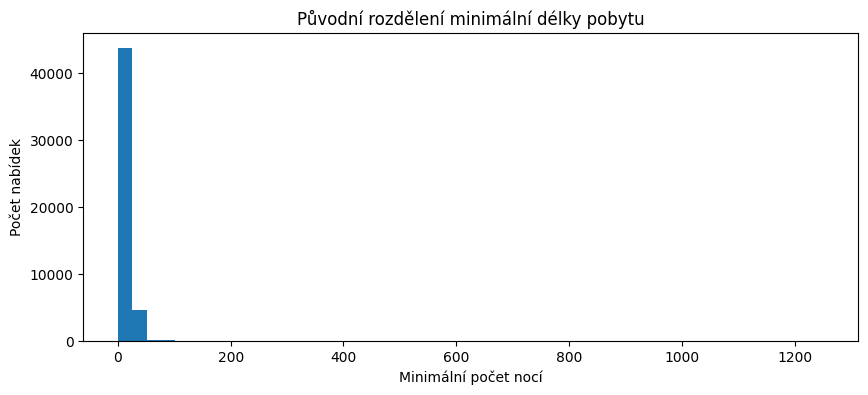

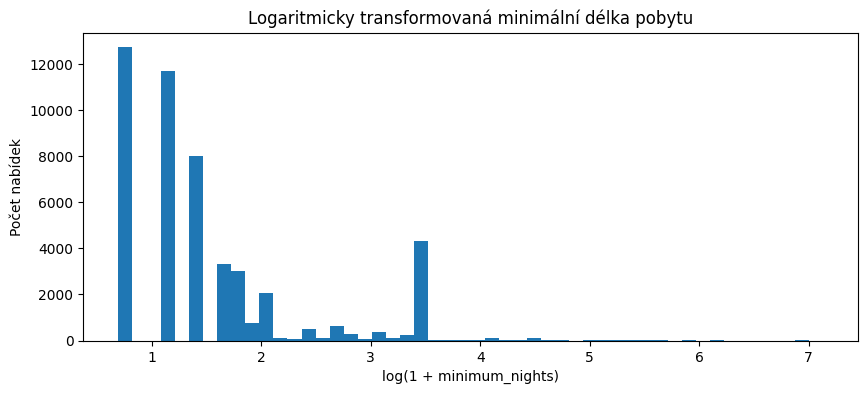

In [180]:

# Porovnani puvodni a logaritmicky transformovane promenne
original = df_features["minimum_nights"]
transformed = np.log1p(original)

plt.figure(figsize=(10, 4))
plt.hist(original, bins=50)
plt.title("Původní rozdělení minimální délky pobytu")
plt.xlabel("Minimální počet nocí")
plt.ylabel("Počet nabídek")
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(transformed, bins=50)
plt.title("Logaritmicky transformovaná minimální délka pobytu")
plt.xlabel("log(1 + minimum_nights)")
plt.ylabel("Počet nabídek")
plt.show()


**Interpretace:**

Původní rozdělení `minimum_nights` je výrazně pravostranně zešikmené. Medián činí 3 noci, zatímco maximální hodnota dosahuje 1 250 nocí.

Po logaritmické transformaci se rozdíly mezi běžnými hodnotami stávají lépe viditelnými a vliv extrémně dlouhých pobytů se snižuje.

Proto použijeme logaritmickou transformaci také u dalších vybraných numerických příznaků s podobným rozdělením.

In [181]:

# Priznaky pro logaritmickou transformaci
skewed_features = [
    "relative_price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count"
]

df_transformed = df_features.copy()

for column in skewed_features:
    df_transformed[column] = np.log1p(df_transformed[column])

display(df_transformed.head())


,log_price,relative_price,minimum_nights,number_of_reviews,reviews_per_month,availability_rate,calculated_host_listings_count,neighbourhood_group,room_type
0,5.010635,1.191589,0.693147,2.302585,0.190620,1.000000,1.945910,Brooklyn,Private room
1,5.420535,0.778412,0.693147,3.828641,0.322083,0.972603,1.098612,Manhattan,Entire home/apt
2,5.017280,0.980829,1.386294,0.000000,0.000000,1.000000,0.693147,Manhattan,Private room
3,4.499810,0.478587,0.693147,5.602119,1.729884,0.531507,0.693147,Brooklyn,Entire home/apt
4,4.394449,0.349845,2.397895,2.302585,0.095310,0.000000,0.693147,Manhattan,Entire home/apt


**Výsledek:**

Logaritmická transformace byla použita na pět příznaků: `relative_price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month` a `calculated_host_listings_count`.

Používáme `log1p(x) = ln(1 + x)` místo `ln(x)`, protože některé příznaky obsahují nuly (například `number_of_reviews = 0` u nabídek bez hodnocení) a `ln(0)` není definován.

Transformace nemění pořadí hodnot, pouze zmenšuje rozdíly mezi velmi vysokými a běžnými hodnotami. Na závěr je potřeba ověřit, nakolik se zešikmení omezilo (sekce 5.5).

### 5.4 Kódování kategoriálních příznaků (One-Hot Encoding)

Algoritmy pracují s čísly, proto musíme převést `neighbourhood_group` (5 kategorií) a `room_type` (3 kategorie) na číselnou podobu. Použijeme One-Hot Encoding: každá kategorie se stane samostatným binárním příznakem (0 nebo 1).

Prosté očíslování kategorií (například Bronx = 1, Brooklyn = 2, Manhattan = 3) by algoritmu vnutilo uměle daná pořadí a vzdálenosti, které v datech neexistují.

Z pěti městských částí a tří typů ubytování tak vzniká 5 + 3 = 8 binárních příznaků. Spolu se sedmi numerickými příznaky dostáváme 15 příznaků.

In [182]:

# Kategoricke priznaky
categorical_features = [
    "neighbourhood_group",
    "room_type"
]

# One-Hot Encoding
df_encoded = pd.get_dummies(
    df_transformed,
    columns=categorical_features,
    dtype=int
)

print("Rozmery pred kodovanim:", df_transformed.shape)
print("Rozmery po kodovani:", df_encoded.shape)

display(df_encoded.head())


Rozmery pred kodovanim: (48884, 9)
Rozmery po kodovani: (48884, 15)


,log_price,relative_price,minimum_nights,number_of_reviews,reviews_per_month,availability_rate,calculated_host_listings_count,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,5.010635,1.191589,0.693147,2.302585,0.190620,1.000000,1.945910,0,1,0,0,0,0,1,0
1,5.420535,0.778412,0.693147,3.828641,0.322083,0.972603,1.098612,0,0,1,0,0,1,0,0
2,5.017280,0.980829,1.386294,0.000000,0.000000,1.000000,0.693147,0,0,1,0,0,0,1,0
3,4.499810,0.478587,0.693147,5.602119,1.729884,0.531507,0.693147,0,1,0,0,0,1,0,0
4,4.394449,0.349845,2.397895,2.302585,0.095310,0.000000,0.693147,0,0,1,0,0,1,0,0


**Výsledek:**

Kategoriální proměnné byly převedeny pomocí One-Hot Encoding. Z devíti příznaků (7 numerických a 2 kategoriální) vzniklo 15 sloupců: 7 numerických a 8 binárních (5 městských částí a 3 typy ubytování).

Dataset nyní obsahuje pouze číselné hodnoty a je připraven ke standardizaci.

**Důsledek pro vzdálenost:** Dvě nabídky, které se liší v kategorii (např. jiná městská část), se liší ve dvou binárních příznacích, a jejich vzdálenost se tedy zvětší o √2 ≈ 1,41. To odpovídá rozdílu 1,41 směrodatné odchylky u standardizovaného numerického příznaku. Kategoriální příznaky proto mají ve vzdálenosti relativně silný vliv. Binární příznaky dále neškálujeme, aby zůstaly interpretovatelné; tuto skutečnost zohledníme při interpretaci DBSCAN (sekce 6.9).

### 5.5 Standardizace příznaků (StandardScaler)

Numerické příznaky mají různá měřítka. `StandardScaler` je převede na průměr 0 a směrodatnou odchylku 1, takže každý příznak přispívá do vzdálenosti srovnatelně. Binární příznaky z One-Hot Encodingu ponecháme beze změny (0 a 1).

Standardizace nemění pořadí ani tvar rozdělení, mění pouze měřítko. Neznamená to, že všechny příznaky mají mít vždy stejnou váhu; jde o rozumný výchozí bod, ne o univerzální pravidlo.

In [211]:
# Kopie zakódovaného datasetu
df_scaled = df_encoded.copy()

# Standardizace numerických příznaků
scaler = StandardScaler()
df_scaled[numerical_features] = scaler.fit_transform(
    df_encoded[numerical_features]
)

# Kontrola 1: numerické příznaky mají průměr 0 a směrodatnou odchylku 1
display(df_scaled[numerical_features].describe().round(2))

# Kontrola 2: dummy příznaky obsahují pouze 0 a 1
dummy_columns = [c for c in df_scaled.columns if c not in numerical_features]
print("Počet dummy příznaků:", len(dummy_columns))
print("Unikátní hodnoty dummy příznaků:",
      np.unique(df_scaled[dummy_columns].to_numpy()))

# Kontrola 3: korelace mezi numerickými příznaky
display(df_scaled[numerical_features].corr().round(2))

,log_price,relative_price,minimum_nights,number_of_reviews,reviews_per_month,availability_rate,calculated_host_listings_count
count,48884.00,48884.00,48884.00,48884.00,48884.00,48884.00,48884.00
mean,0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.38,-2.28,-0.93,-1.27,-0.94,-0.86,-0.46
25%,-0.71,-0.59,-0.93,-0.83,-0.87,-0.86,-0.46
50%,-0.09,-0.16,-0.13,-0.13,-0.39,-0.51,-0.46
75%,0.63,0.33,0.34,0.79,0.70,0.87,0.01
max,6.47,14.45,6.47,2.85,6.13,1.92,5.48


Počet dummy příznaků: 8
Unikátní hodnoty dummy příznaků: [0 1]


,log_price,relative_price,minimum_nights,number_of_reviews,reviews_per_month,availability_rate,calculated_host_listings_count
log_price,1.00,0.74,0.06,-0.07,-0.06,0.10,0.05
relative_price,0.74,1.00,-0.07,-0.09,-0.05,0.16,0.03
minimum_nights,0.06,-0.07,1.00,-0.22,-0.29,0.18,0.34
number_of_reviews,-0.07,-0.09,-0.22,1.00,0.76,0.17,-0.10
reviews_per_month,-0.06,-0.05,-0.29,0.76,1.00,0.20,-0.03
availability_rate,0.10,0.16,0.18,0.17,0.20,1.00,0.40
calculated_host_listings_count,0.05,0.03,0.34,-0.10,-0.03,0.40,1.00


**Interpretace kontroly:**

Všechny numerické příznaky mají průměr 0 a směrodatnou odchylku 1, standardizace tedy proběhla správně.

Logaritmická transformace však zešikmení omezila, ale **neodstranila**. Po standardizaci zůstávají vzdálené hodnoty: `relative_price` až +14,45 směrodatné odchylky, `minimum_nights` +6,47, `reviews_per_month` +6,13 a `calculated_host_listings_count` +5,48. Jde o nabídky s extrémní cenou vůči okolí, velmi dlouhým minimálním pobytem nebo profesionálního hostitele s mnoha nabídkami.

Tyto nabídky jsme v sekci 3 záměrně ponechali, protože nelze prokázat, že jde o chyby. Mohou mírně posouvat centroidy v K-Means. Jejich vliv na DBSCAN posoudíme při interpretaci šumu (sekce 6.9).

**Korelace mezi příznaky.** Většina numerických příznaků je navzájem slabě korelována (převážně do 0,3 v absolutní hodnotě), takže každý z nich přináší převážně odlišnou informaci. Dvě dvojice ale vykazují silnější vazbu:

- `log_price` a `relative_price` (r = 0,74): oba vycházejí z ceny. Obě proměnné ponecháváme, protože odpovídají na jinou otázku (absolutní × relativní cena), cena ale má ve vzdálenosti přibližně dvojnásobný vliv.
- `number_of_reviews` a `reviews_per_month` (r = 0,76): oba popisují aktivitu hodnocení. První udává celkový počet za dobu existence nabídky, druhý aktuální frekvenci, takže rozlišují například dlouho zavedenou nabídku od nové, ale velmi aktivní. I zde mají hodnocení ve vzdálenosti větší váhu.

Korelace jsou střední až vyšší, ne téměř úplné (r > 0,9), proto žádný příznak neodstraňujeme. Vliv těchto dvojic ale zohledníme při interpretaci a uvedeme jej mezi omezeními.

### 5.6 Shrnutí přípravy dat

| Krok | Co jsme udělali | Proč |
|---|---|---|
| Výběr | 9 příznaků (7 numerických, 2 kategoriální) | Popisují cenu, pobyt, hodnocení, dostupnost, hostitele, lokalitu a typ |
| Logaritmus | `log1p` na 5 zešikmených příznaků | Omezení vlivu extrémních hodnot |
| One-Hot | 8 binárních příznaků | Převod kategorií na čísla bez umělého pořadí |
| Standardizace | pouze 7 numerických příznaků | Srovnatelný příspěvek do vzdálenosti |

Výsledná matice má **48 884 záznamů a 15 příznaků** a používají ji oba algoritmy (K-Means i DBSCAN). Zbytkové extrémní hodnoty a relativně silný vliv kategorií jsou omezení, ke kterým se vrátíme při interpretaci.

**Omezení přípravy dat:**

- Logaritmus zešikmení omezil, ale neodstranil (hodnoty až +14,45 SD).
- Cena (`log_price`, `relative_price`) a aktivita hodnocení (`number_of_reviews`, `reviews_per_month`) mají ve vzdálenosti vyšší váhu, protože jsou reprezentovány dvěma korelovanými příznaky.
- Binární příznaky nejsou škálovány, jejich rozdíl přidává ke vzdálenosti √2 ≈ 1,41.

## 6. Shluková analýza

### 6.1 K-Means: volba počtu shluků

K-Means vyžaduje počet shluků K předem. Algoritmus přiřazuje každou nabídku k nejbližšímu centroidu a centroidy přepočítává jako průměr přiřazených bodů. Vhodné K proto hledáme z více ukazatelů, žádný z nich ale není rozhodující:

- **Inertia** je součet čtverců vzdáleností bodů od jejich centroidů. S rostoucím K vždy klesá, proto nás zajímá, kde se pokles výrazně zpomalí (metoda lokte).
- **Silhouette Score** kombinuje soudržnost uvnitř shluku a oddělení od sousedního shluku (vyšší hodnota je lepší). Počítáme ho na náhodném vzorku 5 000 nabídek, aby byl výpočet rychlý. Samotné modely se trénují na celém datasetu.
- **Velikost nejmenšího shluku** upozorní na příliš malé, těžko interpretovatelné skupiny.

Testujeme K = 2 až 10. Nejprve jsou na jednom místě výsledky všech tří ukazatelů.

,K,inertia,silhouette,nejmenší shluk (%),pokles inertie
0,2,326858.060,0.188,38.041,NaN
1,3,274308.979,0.222,9.124,52549.081
2,4,236273.244,0.225,7.606,38035.735
3,5,215626.915,0.191,6.466,20646.328
4,6,198595.561,0.193,4.597,17031.354
5,7,185325.566,0.192,4.505,13269.996
6,8,174682.171,0.191,4.482,10643.395
7,9,166969.624,0.181,2.682,7712.547
8,10,161077.043,0.176,2.729,5892.581


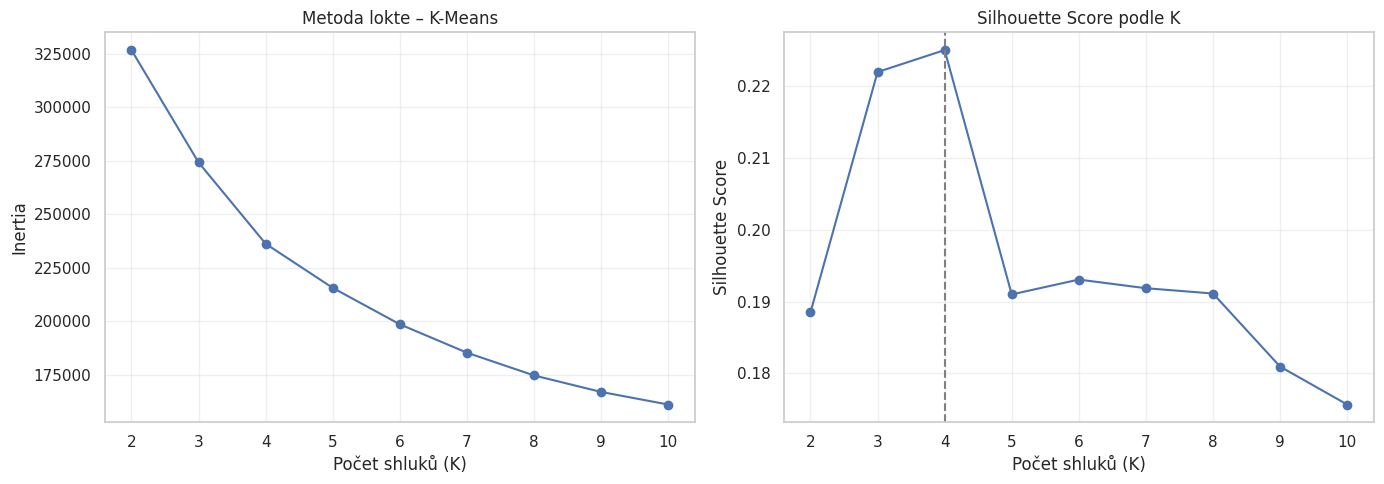

In [212]:
k_values = range(2, 11)
kmeans_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(df_scaled)

    kmeans_scores.append({
        "K": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(
            df_scaled, labels, sample_size=5000, random_state=RANDOM_STATE
        ),
        "nejmenší shluk (%)": pd.Series(labels).value_counts(normalize=True).min() * 100,
    })

kmeans_scores = pd.DataFrame(kmeans_scores)
kmeans_scores["pokles inertie"] = -kmeans_scores["inertia"].diff()
display(kmeans_scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(kmeans_scores["K"], kmeans_scores["inertia"], marker="o")
axes[0].set_title("Metoda lokte – K-Means")
axes[0].set_xlabel("Počet shluků (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(kmeans_scores["K"], kmeans_scores["silhouette"], marker="o")
axes[1].axvline(4, linestyle="--", color="gray")
axes[1].set_title("Silhouette Score podle K")
axes[1].set_xlabel("Počet shluků (K)")
axes[1].set_ylabel("Silhouette Score")

for axis in axes:
    axis.set_xticks(list(k_values))
    axis.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 6.2 Výběr počtu shluků

- **Inertia** klesá s každým dalším shlukem. Pokles při přidání čtvrtého shluku je 38 tisíc, při přidání pátého jen 21 tisíc, tedy po K = 4 se přírůstek výrazně zmenšuje. Ostrý „loket“ ale graf nemá.
- **Silhouette Score** je nejvyšší pro K = 4 (0,225) a téměř stejně vysoký pro K = 3 (0,222). Pro K = 5 klesá na 0,191 a pro vyšší K zůstává kolem 0,19 a dále klesá. Rozdíl mezi K = 3 a K = 4 (0,003) je malý a hodnota je odhadnuta z náhodného vzorku 5 000 nabídek, takže tyto dvě varianty považujeme za téměř rovnocenné.
- **Velikost nejmenšího shluku:** při K = 4 tvoří 7,6 % nabídek (při K = 3 je to 9,1 %), žádná skupina tedy není zanedbatelně malá.

**Rozhodnutí:** zvolíme K = 4, protože má nejvyšší Silhouette Score, pokles inertie se po něm zpomaluje a čtyři shluky lze věcně popsat (sekce 6.5).

**Omezení:** Silhouette Score 0,225 je nízký, shluky se tedy do značné míry překrývají. Volba K = 4 není „jediné správné řešení“, ale nejlépe podložený kompromis. Výsledky pro K = 3 jsme věcně nesrovnávali, což by bylo logickým dalším krokem.

### 6.3 Finální model K-Means

Podle sekce 6.1 trénujeme K-Means s K = 4 na všech 48 884 nabídkách a každé nabídce přiřadíme číslo shluku. Čísla shluků jsou jen označení: nenesou žádný význam a při jiném `random_state` se mohou přečíslovat. Význam shlukům dáme až interpretací pomocí původních proměnných.

In [187]:

# Finalni model K-Means
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(df_scaled)

df_clean["cluster"] = cluster_labels

# Pocet nabidek v jednotlivych shlucich
cluster_counts = df_clean["cluster"].value_counts().sort_index()

display(cluster_counts)


cluster
0     3718
1    22547
2    16067
3     6552
Name: count, dtype: int64

**Velikosti shluků:** shluk 0 má 3 718 nabídek (7,6 %), shluk 1 má 22 547 (46,1 %), shluk 2 má 16 067 (32,9 %) a shluk 3 má 6 552 (13,4 %). Shluky nejsou vyrovnané, ale žádný není zanedbatelně malý.

### 6.4 Charakteristika nalezených shluků

Pro interpretaci shluků nejprve porovnáme mediánové hodnoty numerických proměnných. Následně analyzujeme zastoupení typů ubytování a městských částí v jednotlivých shlucích.

In [188]:

# Medianove hodnoty v jednotlivych shlucich
cluster_profile = df_clean.groupby("cluster")[
    [
        "price",
        "minimum_nights",
        "number_of_reviews",
        "reviews_per_month",
        "availability_365",
        "calculated_host_listings_count"
    ]
].median().round(2)

display(cluster_profile)


,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365,calculated_host_listings_count
cluster,,,,,,
0,150.0,30.0,1.0,0.07,323.0,29.0
1,95.0,3.0,2.0,0.10,0.0,1.0
2,95.0,2.0,39.0,2.28,151.0,1.0
3,300.0,3.0,3.0,0.22,97.0,1.0


**Shrnutí tabulek:**

- Medián ceny je v shlucích 1 a 2 stejný (95 USD), v shluku 0 je 150 USD a v shluku 3 je 300 USD, tedy zhruba třikrát vyšší.
- Shluk 0 se zásadně liší délkou pobytu (medián 30 nocí proti 2–3), dostupností (323 dní) a počtem nabídek na hostitele (medián 29 proti 1).
- Shluky 1 a 2 mají velmi podobné složení podle typu ubytování (47 % a 45 % celých bytů) i ceny. Liší se hlavně dostupností (medián 0 a 151 dní) a hodnocením (medián 2 a 39 hodnocení).
- Manhattan převažuje ve shlucích 0 (71,9 %) a 3 (57,9 %), kdežto shluky 1 a 2 jsou více rozložené mezi Brooklyn a Manhattan.

### Zastoupení typů ubytování

Pro každý shluk vypočítáme procentuální zastoupení jednotlivých typů ubytování. To nám umožní zjistit, zda některé shluky tvoří převážně celé byty, nebo soukromé pokoje.

In [189]:

# Procentualni zastoupeni typu ubytovani
room_distribution = pd.crosstab(
    df_clean["cluster"],
    df_clean["room_type"],
    normalize="index"
) * 100

display(room_distribution.round(2))


room_type,Entire home/apt,Private room,Shared room
cluster,,,
0,69.90,26.49,3.60
1,47.10,50.85,2.04
2,45.02,52.21,2.77
3,75.63,22.57,1.80


### Geografické rozložení shluků

Dále porovnáme procentuální zastoupení městských částí v jednotlivých shlucích, abychom zjistili, zda mají nalezené skupiny také geografické charakteristiky.

In [190]:

# Procentualni zastoupeni mestskych casti
location_distribution = pd.crosstab(
    df_clean["cluster"],
    df_clean["neighbourhood_group"],
    normalize="index"
) * 100

display(location_distribution.round(2))


neighbourhood_group,Bronx,Brooklyn,Manhattan,Queens,Staten Island
cluster,,,,,
0,0.94,19.15,71.92,7.85,0.13
1,1.80,46.48,41.63,9.67,0.43
2,3.47,42.32,36.13,16.72,1.36
3,1.40,32.11,57.92,7.75,0.81


### 6.5 Interpretace výsledků K-Means

K-Means rozdělil 48 884 nabídek do čtyř shluků. Názvy níže jsou opatrné popisy, nikoli pevné kategorie: každý shluk obsahuje také výjimky.

**Shluk 0 – dlouhodobé pobyty a hostitelé s více nabídkami (3 718 nabídek, 7,6 %)**
Medián minimálního pobytu je 30 nocí, medián počtu nabídek na hostitele 29 a medián dostupnosti 323 dní za rok. Z 69,9 % jde o celé byty nebo domy a 71,9 % nabídek je na Manhattanu. Medián ceny (150 USD) je vyšší než u shluků 1 a 2. Hodnocení jsou řídká (medián 1). Profil odpovídá měsíčním pronájmům spravovaným hostiteli s mnoha nabídkami. Shluk ale obsahuje i 26,5 % soukromých pokojů, takže nejde výhradně o celé byty.

**Shluk 1 – nabídky s nulovou dostupností a málo hodnoceními (22 547 nabídek, 46,1 %)**
Nejlidnatější shluk má medián ceny 95 USD, medián dostupnosti 0 dní a medián pouhých 2 hodnocení (0,10 hodnocení měsíčně). Typy ubytování jsou vyrovnané (47,1 % celých bytů, 50,9 % soukromých pokojů). Nulová dostupnost může znamenat plnou obsazenost, zablokovaný kalendář i neaktivní nabídku, a z dat to rozlišit nelze.

**Shluk 2 – aktivní a často hodnocené nabídky (16 067 nabídek, 32,9 %)**
Medián ceny je stejný jako u shluku 1 (95 USD), ale medián počtu hodnocení je 39, hodnocení měsíčně 2,28 a dostupnost 151 dní. Složení podle typu ubytování je podobné jako u shluku 1 (45,0 % celých bytů). Tento shluk má největší podíl Queensu (16,7 %) mezi všemi shluky. Vysoký počet hodnocení může odrážet i delší dobu existence nabídky, proto popis „aktivní“ opíráme o frekvenci hodnocení za měsíc, ne o jejich celkový počet.

**Shluk 3 – dražší ubytování (6 552 nabídek, 13,4 %)**
Medián ceny je 300 USD za noc, tedy zhruba třikrát vyšší než u shluků 1 a 2. Celé byty tvoří 75,6 % nabídek a 57,9 % jich leží na Manhattanu. Hodnocení jsou spíše řídká (medián 3). Shluk obsahuje i 22,6 % soukromých pokojů, takže vysoká cena nesouvisí jen s typem ubytování.

**Celkové vyhodnocení.** Shluky se liší hlavně délkou pobytu a typem hostitele (shluk 0), aktivitou hodnocení a dostupností (shluky 1 a 2) a cenou (shluk 3). Typ ubytování a městská část rozlišují shluky jen částečně. Shluky 1 a 2 se téměř neliší cenou ani typem ubytování, odlišuje je hlavně aktivita hodnocení. To odpovídá skutečnosti, že hodnocení jsou ve vzdálenostech zastoupena dvěma korelovanými příznaky (sekce 5.5). Silhouette Score 0,225 navíc ukazuje na překrývání shluků, proto jde o přibližné segmenty trhu.

### 6.6 Shlukování pomocí DBSCAN

Jako druhou metodu shlukování použijeme DBSCAN. Na rozdíl od K-Means tento algoritmus nevyžaduje předem určit počet shluků a dokáže identifikovat také šumové body.

Kvůli vyšší výpočetní náročnosti použijeme náhodný vzorek 5 000 nabídek. Parametry `eps` a `min_samples` následně ověříme a vybereme vhodnou konfiguraci.

In [221]:
# Nahodny vzorek pro DBSCAN
dbscan_sample = df_scaled.sample(
    n=5000,
    random_state=42
)

print("Rozmery vzorku:", dbscan_sample.shape)


Rozmery vzorku: (5000, 15)


In [222]:

# Kontrola reprezentativnosti nahodneho vzorku
sample_original = df_clean.loc[dbscan_sample.index]

for column in ["room_type", "neighbourhood_group"]:
    comparison = pd.DataFrame({
        "Cely dataset (%)": df_clean[column].value_counts(normalize=True) * 100,
        "Vzorek 5000 (%)": sample_original[column].value_counts(normalize=True) * 100
    })

    print(f"\nPorovnani: {column}")
    display(comparison.round(2))



Porovnani: room_type


,Cely dataset (%),Vzorek 5000 (%)
room_type,,
Entire home/apt,51.97,51.56
Private room,45.66,46.06
Shared room,2.37,2.38



Porovnani: neighbourhood_group


,Cely dataset (%),Vzorek 5000 (%)
neighbourhood_group,,
Manhattan,44.31,43.48
Brooklyn,41.11,41.24
Queens,11.59,11.88
Bronx,2.23,2.46
Staten Island,0.76,0.94


Zastoupení typů ubytování i městských částí ve vzorku 5 000 nabídek se jen málo liší od celého datasetu, vzorek je tedy dostatečně reprezentativní pro použití v DBSCAN a v porovnání metod.

### 6.7 Výběr parametrů DBSCAN

DBSCAN má dva parametry: `eps` (poloměr okolí) a `min_samples` (minimální počet bodů v okolí potřebný pro hustou oblast). Nevyžaduje počet shluků, ale vyžaduje hustotní škálu. Otázka „kolik shluků?“ se tak mění na otázku „jak hustá oblast se má považovat za shluk?“.

**`min_samples = 30`.** Podle běžného pravidla by `min_samples` mělo být alespoň počet příznaků + 1 a často se volí přibližně dvojnásobek počtu příznaků. Máme 15 příznaků, proto 30. Příliš malá hodnota by v 15rozměrném prostoru snadno považovala za hustou oblast i náhodné seskupení bodů.

**Graf vzdáleností k 30. sousedovi.** Pro většinu pozorování roste vzdálenost pozvolna z přibližně 0,5 na přibližně 2. Prudký nárůst nastává až u posledních několika procent bodů (maximum kolem 7,5), což jsou izolovaná pozorování. Jednoznačný ostrý loket graf nemá, protože hustota nabídek se mění plynule. Graf proto používáme jako orientaci a kandidáty na `eps` ověřujeme přímo.

**Porovnání hodnot `eps`:**

| `eps` | Počet shluků | Šum (%) | Co se děje |
|---|---|---|---|
| 1,2 | 7 | 33,18 | roztříštění na malé shluky a velký podíl šumu |
| 1,5 | 3 | 15,52 | několik odlišných skupin a přijatelný šum |
| 1,8 | 1 | 4,94 | skupiny se spojí do jednoho shluku |
| 2,0 | 1 | 2,64 | totéž |
| 2,3 | 1 | 1,26 | totéž |

**Rozhodnutí:** zvolíme `eps = 1,5` a `min_samples = 30`. Je to největší vyzkoušená hodnota, při které DBSCAN ještě rozlišuje více skupin. Při menším `eps` se data roztříští a polovina bodů se stane šumem, při větším splynou do jedné skupiny.

**Omezení:** Výsledek je citlivý na `eps`: mezi 1,5 a 1,8 se struktura zhroutí do jednoho shluku. Hodnoty jsme navíc testovali jen na vzorku 5 000 nabídek.

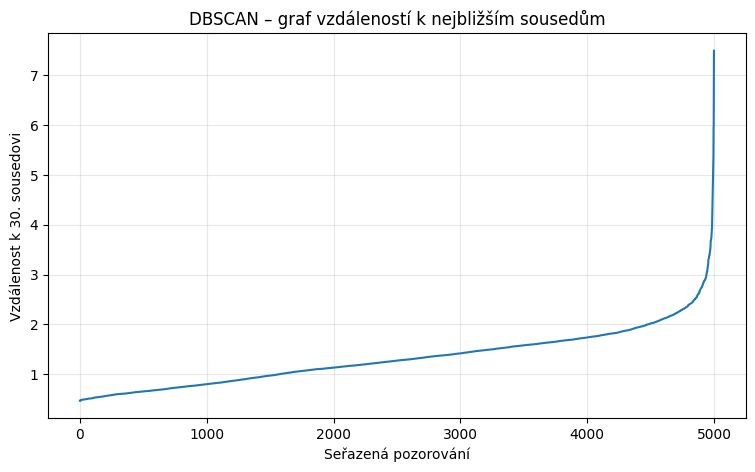

In [192]:

# Graf vzdalenosti k 30. nejblizsimu sousedovi
min_samples = 30

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(dbscan_sample)

distances, _ = neighbors.kneighbors(dbscan_sample)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)

plt.title("DBSCAN – graf vzdáleností k nejbližším sousedům")
plt.xlabel("Seřazená pozorování")
plt.ylabel("Vzdálenost k 30. sousedovi")
plt.grid(alpha=0.3)
plt.show()


In [193]:

# Porovnani ruznych hodnot eps
results = []

for eps in [1.2, 1.5, 1.8, 2.0, 2.3]:
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    labels = model.fit_predict(dbscan_sample)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_percentage = (labels == -1).mean() * 100

    results.append({
        "eps": eps,
        "Pocet shluku": n_clusters,
        "Sum (%)": round(noise_percentage, 2)
    })

dbscan_results = pd.DataFrame(results)
display(dbscan_results)


,eps,Pocet shluku,Sum (%)
0,1.2,7,33.18
1,1.5,3,15.52
2,1.8,1,4.94
3,2.0,1,2.64
4,2.3,1,1.26


**Vyhodnocení parametrů:**

Při menších hodnotách `eps` vzniká více shluků, ale zároveň roste podíl šumových bodů. Při vyšších hodnotách `eps` dochází ke spojování shluků.

Pro další analýzu jsme zvolili `eps = 1,5` a `min_samples = 30`. Tato konfigurace identifikovala tři shluky a 15,52 % šumových bodů.

Zvolená hodnota představuje kompromis mezi rozlišením skupin a podílem pozorování označených jako šum.

### 6.8 Finální model DBSCAN a charakteristika shluků

Finální model DBSCAN použijeme na vzorku 5 000 nabídek s parametry `eps = 1,5` a `min_samples = 30`.

Pro nalezené shluky vypočítáme jejich velikost a mediánové hodnoty vybraných charakteristik. Šumové body označené hodnotou −1 ponecháme ve výsledné tabulce pro samostatné porovnání.

In [194]:

# Finalni model DBSCAN
dbscan_final = DBSCAN(
    eps=1.5,
    min_samples=30
)

dbscan_labels_final = dbscan_final.fit_predict(dbscan_sample)

# Prirazeni shluku k puvodnim udajum
dbscan_profile = df_clean.loc[dbscan_sample.index].copy()
dbscan_profile["dbscan_cluster"] = dbscan_labels_final

# Velikost jednotlivych shluku
cluster_sizes = dbscan_profile["dbscan_cluster"].value_counts().sort_index()
display(cluster_sizes)

# Medianove charakteristiky shluku
dbscan_summary = dbscan_profile.groupby("dbscan_cluster")[
    [
        "price",
        "minimum_nights",
        "number_of_reviews",
        "reviews_per_month",
        "availability_365",
        "calculated_host_listings_count"
    ]
].median().round(2)

display(dbscan_summary)


dbscan_cluster
-1     776
 0    1950
 1    2109
 2     165
Name: count, dtype: int64

,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365,calculated_host_listings_count
dbscan_cluster,,,,,,
-1,100.0,3.0,5.0,0.49,259.5,2.0
0,69.0,2.0,5.0,0.38,16.0,1.0
1,150.0,3.0,6.0,0.40,14.0,1.0
2,190.0,30.0,1.0,0.01,331.0,87.0


In [195]:

# Typy ubytovani v jednotlivych shlucich
room_dbscan = pd.crosstab(
    dbscan_profile["dbscan_cluster"],
    dbscan_profile["room_type"],
    normalize="index"
) * 100

display(room_dbscan.round(2))


room_type,Entire home/apt,Private room,Shared room
dbscan_cluster,,,
-1,39.18,46.78,14.05
0,0.00,99.49,0.51
1,100.00,0.00,0.00
2,100.00,0.00,0.00


### 6.9 Interpretace shluků DBSCAN

DBSCAN našel na vzorku 5 000 nabídek tři shluky a označil 776 nabídek (15,52 %) za šum.

**Shluk 0 – soukromé pokoje s nízkou dostupností (1 950 nabídek, 39,0 %).** Tvoří jej z 99,49 % soukromé pokoje. Medián ceny je 69 USD, minimální pobyt 2 noci a medián dostupnosti 16 dní. Hostitelé mají typicky jednu nabídku.

**Shluk 1 – celé byty a domy pro krátkodobé pobyty (2 109 nabídek, 42,2 %).** Všechny nabídky jsou celé byty nebo domy. Medián ceny je 150 USD, minimální pobyt 3 noci a medián dostupnosti 14 dní.

**Shluk 2 – dlouhodobé pobyty a profesionální hostitelé (165 nabídek, 3,3 %).** Jde také o celé byty nebo domy. Od shluku 1 se liší mediánem minimálního pobytu 30 nocí, 87 nabídkami na hostitele a dostupností 331 dní. Medián ceny je 190 USD a hodnocení jsou řídká (medián 1).

**Šum (776 nabídek, 15,52 %).** Medián ceny šumu je 100 USD, tedy běžná hodnota. Šum se od hustých shluků liší hlavně dostupností (medián 259,5 dne proti 14 až 16 dnům) a podílem sdílených pokojů (14,05 % proti přibližně 2,4 % ve vzorku): téměř všechny sdílené pokoje ve vzorku (přibližně 109 ze 119) skončily v šumu. Šum tedy tvoří nabídky v řídce obsazených oblastech prostoru příznaků, ne primárně nabídky s extrémní cenou. 

**Co DBSCAN skutečně rozlišuje.** Shluky 0 a 1 se od sebe liší téměř výhradně typem ubytování. To je pravděpodobně důsledek geometrie dat: změna typu ubytování posune nabídku o √2 ≈ 1,41 ve dvou binárních příznacích, což je blízko hodnotě `eps = 1,5` (sekce 5.4). Hustotní metoda tak do značné míry znovu objevuje typ ubytování. Shluk 2 je naproti tomu informativnější, protože ho odlišují délka pobytu, dostupnost a velikost hostitele.

**Shoda s K-Means.** Shluk 2 odpovídá K-Means shluku 0 (minimální pobyt 30 nocí, vysoká dostupnost 323 a 331 dní, hostitelé s mnoha nabídkami). Dvě odlišné metody tedy nezávisle našly stejnou skupinu, což zvyšuje důvěru v její existenci.

In [213]:
sample_scaled = df_scaled.loc[dbscan_sample.index, numerical_features]
has_extreme = (sample_scaled.abs() > 3).any(axis=1)
is_noise = pd.Series(dbscan_labels_final == -1, index=dbscan_sample.index)

display(pd.crosstab(is_noise, has_extreme, normalize="index").mul(100).round(1))

col_0,False,True
row_0,,
False,96.8,3.2
True,79.4,20.6


### 6.10 Porovnání K-Means a DBSCAN

Pro porovnání obou algoritmů použijeme metriku Silhouette Score na vzorku 5 000 nabídek.

Model K-Means byl natrénován na celém datasetu, zatímco DBSCAN pouze na vybraném vzorku.

U algoritmu DBSCAN vyloučíme při výpočtu Silhouette Score šumové body (−1), protože netvoří samostatný běžný shluk. Jejich podíl uvedeme zvlášť.

Výsledky proto budeme interpretovat s ohledem na rozdílné podmínky vyhodnocení.

In [196]:

# Porovnani K-Means a DBSCAN na stejnem vzorku

# Prirazeni shluku modelem K-Means
kmeans_sample_labels = kmeans_final.predict(dbscan_sample)

kmeans_score = silhouette_score(
    dbscan_sample,
    kmeans_sample_labels
)

# Vylouceni sumovych bodu DBSCAN
mask = dbscan_labels_final != -1

dbscan_score = silhouette_score(
    dbscan_sample.loc[mask],
    dbscan_labels_final[mask]
)

noise_percentage = (~mask).mean() * 100

print(f"K-Means Silhouette Score: {kmeans_score:.4f}")
print(f"DBSCAN Silhouette Score: {dbscan_score:.4f}")
print(f"Podil sumovych bodu DBSCAN: {noise_percentage:.2f} %")


K-Means Silhouette Score: 0.2250
DBSCAN Silhouette Score: 0.1799
Podil sumovych bodu DBSCAN: 15.52 %


**Interpretace výsledků:**

Obě hodnoty jsou počítány na stejném vzorku 5 000 nabídek (hodnota pro K-Means se shoduje se sekcí 6.1). K-Means dosáhl Silhouette Score **0,2250**, DBSCAN **0,1799** po vyloučení 15,52 % šumových bodů.

Nižší hodnotu DBSCAN nelze číst jako důkaz, že je metoda horší. Silhouette Score z definice zvýhodňuje kompaktní, shodně velké shluky, na které je K-Means stavěn, kdežto DBSCAN hledá hustotní oblasti. Metody navíc odpovídají na různé otázky: K-Means rozdělí všechny nabídky do čtyř segmentů, DBSCAN najde husté skupiny a označí neobvyklé nabídky. Obě hodnoty jsou nízké, tedy shluky se u obou metod překrývají.

**Omezení:** K-Means byl natrénován na celém datasetu, DBSCAN pouze na vzorku, a DBSCAN je hodnocen bez šumových bodů.

**Závěr:** Jako hlavní metodu segmentace používáme K-Means, DBSCAN slouží jako doplňující pohled (identifikace šumu, nezávislé potvrzení skupiny dlouhodobých pobytů).

In [214]:
mask = dbscan_labels_final != -1
fair_kmeans = silhouette_score(dbscan_sample.loc[mask], kmeans_sample_labels[mask])
print(f"K-Means Silhouette na stejných bodech jako DBSCAN: {fair_kmeans:.4f}")

K-Means Silhouette na stejných bodech jako DBSCAN: 0.2229


Hodnotíme-li K-Means jen na bodech, které DBSCAN nepovažuje za šum, dosahuje Silhouette Score 0,2229, tedy stále více než DBSCAN (0,1799). Vyšší hodnota K-Means tedy nevzniká pouhým vyloučením šumu.

In [223]:
overlap = pd.crosstab(
    pd.Series(dbscan_labels_final, name="DBSCAN"),
    pd.Series(kmeans_sample_labels, name="K-Means")
)
display(overlap)

K-Means,0,1,2,3
DBSCAN,,,,
-1,161,131,245,239
0,1,1133,746,70
1,22,1075,646,366
2,165,0,0,0


**Interpretace:**

Všech 165 nabídek DBSCAN shluku 2 leží v K-Means shluku 0, v jiných shlucích K-Means se žádná z nich nenachází. Naopak K-Means shluk 0 obsahuje ve vzorku 349 nabídek: 165 z nich (47 %) DBSCAN zařadil do shluku 2, 161 (46 %) označil za šum a 23 přiřadil k jiným shlukům. DBSCAN shluk 2 je tedy hustým jádrem skupiny dlouhodobých pobytů, kterou K-Means vymezil šířeji.

Shluky 0 a 1 z DBSCAN se naopak rozkládají přes K-Means shluky 1 až 3 bez zřetelné shody. Odpovídá to zjištění, že tyto dva shluky DBSCAN rozlišují hlavně typ ubytování, zatímco K-Means dělí nabídky podle hodnocení, dostupnosti a ceny.

### 6.11 Vizualizace shluků pomocí PCA

Pro přehlednější zobrazení výsledků použijeme metodu PCA (Principal Component Analysis), která převede původní vícerozměrná data do dvou hlavních komponent.

PCA zde slouží pouze k vizualizaci shluků. Samotné algoritmy K-Means a DBSCAN byly trénovány na původních předzpracovaných datech.

Vysvetlena variance 1. komponenty: 25.56 %
Vysvetlena variance 2. komponenty: 22.63 %
Celkova vysvetlena variance: 48.19 %


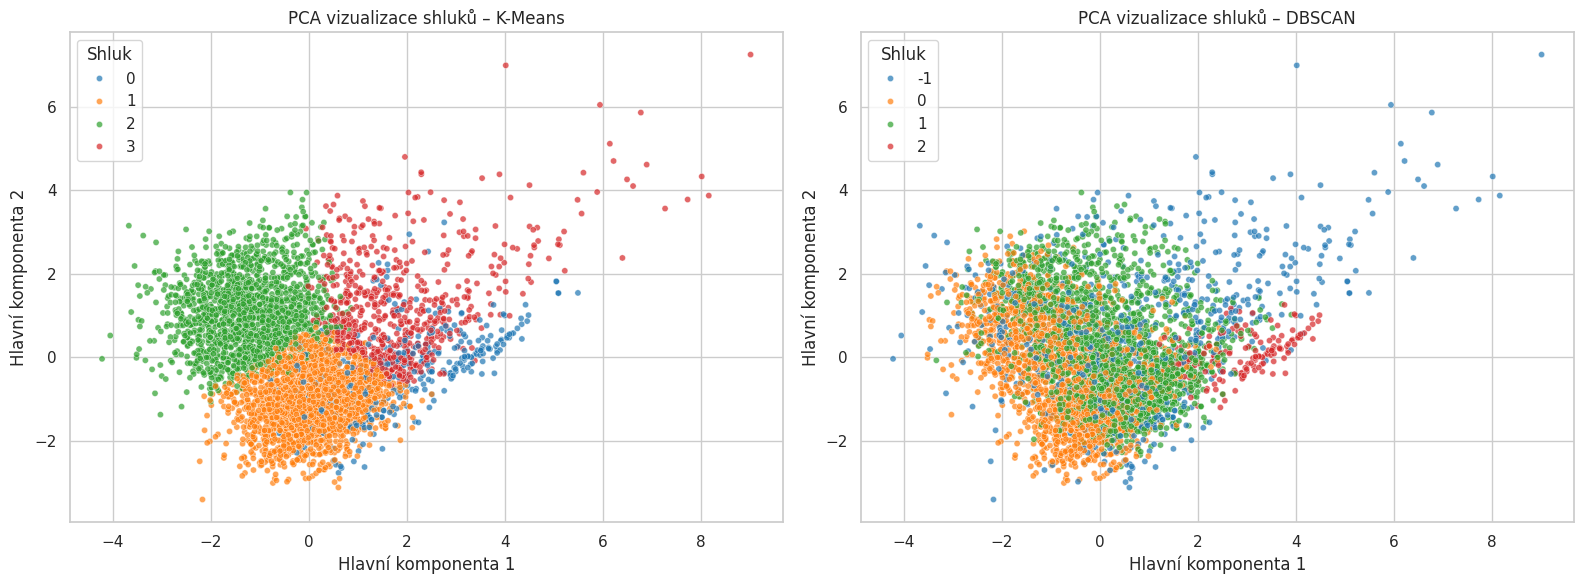

In [219]:
# PCA na stejnem vzorku 5000 zaznamu
pca = PCA(n_components=2, random_state=42)
dbscan_sample_pca = pca.fit_transform(dbscan_sample)

print("Vysvetlena variance 1. komponenty:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("Vysvetlena variance 2. komponenty:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")
print("Celkova vysvetlena variance:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means
sns.scatterplot(
    x=dbscan_sample_pca[:, 0],
    y=dbscan_sample_pca[:, 1],
    hue=kmeans_sample_labels,
    palette="tab10",
    s=20,
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title("PCA vizualizace shluků – K-Means")
axes[0].set_xlabel("Hlavní komponenta 1")
axes[0].set_ylabel("Hlavní komponenta 2")
axes[0].legend(title="Shluk")

# DBSCAN
sns.scatterplot(
    x=dbscan_sample_pca[:, 0],
    y=dbscan_sample_pca[:, 1],
    hue=dbscan_labels_final,
    palette="tab10",
    s=20,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title("PCA vizualizace shluků – DBSCAN")
axes[1].set_xlabel("Hlavní komponenta 1")
axes[1].set_ylabel("Hlavní komponenta 2")
axes[1].legend(title="Shluk")

plt.tight_layout()
plt.show()

**Interpretace PCA vizualizace:**

První dvě hlavní komponenty vysvětlují 25,56 % a 22,63 % variability, dohromady 48,19 %. Projekce proto zachycuje jen necelou polovinu informace.

U **K-Means** vidíme čtyři oblasti, které na sebe plynule navazují, bez zřetelných mezer. Shluky tedy dělí souvislý oblak bodů na části, což odpovídá nízkému Silhouette Score (0,225). Shluk 0 tvoří úzký pruh vpravo dole.

U **DBSCAN** se tři shluky v projekci silně překrývají, protože dělicí příznaky (typ ubytování jako binární příznak) se do prvních dvou komponent promítnou jen částečně. Šum je rozptýlen po okrajích i uvnitř oblaku. Shluk 2 vytváří stejný pruh vpravo dole jako K-Means shluk 0, což potvrzuje shodu obou metod.

**Omezení:** PCA je jen vizualizace. Překrývání v projekci nemusí přesně odpovídat oddělení v původním 15rozměrném prostoru.

### 6.12 Vizualizace profilů shluků K-Means

Pro přehlednější porovnání čtyř shluků zobrazíme teplotní mapu jejich mediánových charakteristik.

Hodnoty standardizujeme podle jednotlivých příznaků, aby bylo možné porovnat jejich relativní rozdíly mezi shluky.

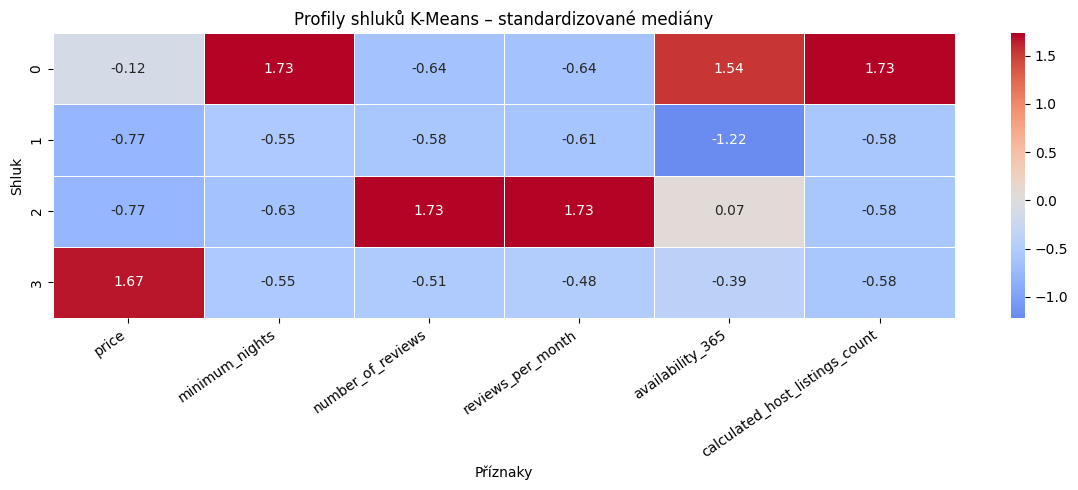

In [197]:

# Vyber charakteristik shluku
profile_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365",
    "calculated_host_listings_count"
]

# Medianove hodnoty
cluster_medians = df_clean.groupby("cluster")[profile_columns].median()

# Standardizace pro vizualizaci
cluster_heatmap = (
    cluster_medians - cluster_medians.mean()
) / cluster_medians.std(ddof=0)

plt.figure(figsize=(12, 5))

sns.heatmap(
    cluster_heatmap,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Profily shluků K-Means – standardizované mediány")
plt.xlabel("Příznaky")
plt.ylabel("Shluk")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


**Interpretace:**

Teplotní mapa zobrazuje mediány jednotlivých příznaků ve shlucích, standardizované napříč čtyřmi shluky. Červená označuje vyšší, modrá nižší hodnoty. Protože standardizujeme jen čtyři hodnoty, mapa rozdíly zvýrazňuje; přesná čísla proto vždy čteme z tabulky v sekci 6.4.

- **Shluk 0:** nejdelší minimální pobyt (30 nocí), nejvyšší dostupnost (323 dní) a nejvíce nabídek na hostitele (29).
- **Shluk 1:** nulová mediánová dostupnost a málo hodnocení.
- **Shluk 2:** nejvyšší aktivita hodnocení (medián 39 hodnocení, 2,28 měsíčně).
- **Shluk 3:** nejvyšší cena (300 USD).

Mapa potvrzuje popis z sekce 6.5. Shluky 1 a 2 se liší hlavně dostupností a hodnoceními, nikoli cenou.

### 6.13 Ověření stability K-Means

Algoritmus K-Means začíná z náhodně umístěných centroidů a může skončit v různých lokálních řešeních. Zkoumáme proto, zda výsledek závisí na náhodné inicializaci: pro deset hodnot `random_state` porovnáváme rozdělení s referenčním během (seed 0) pomocí Adjusted Rand Index (ARI). ARI = 1 znamená shodné rozdělení bez ohledu na číslování shluků. Testujeme `n_init = 1` (jedna inicializace) a `n_init = 10` (nejlepší z deseti inicializací) na vzorku 5 000 nabídek.

In [220]:
# Overeni stability K-Means
for n_init in [1, 10]:

    stability_labels = []

    # Deset ruznych nahodnych inicializaci
    for seed in range(10):
        model = KMeans(
            n_clusters=4,
            random_state=seed,
            n_init=n_init
        )

        labels = model.fit_predict(dbscan_sample)
        stability_labels.append(labels)

    # Porovnani s prvnim vysledkem
    reference = stability_labels[0]

    ari_scores = []

    for labels in stability_labels[1:]:
        score = adjusted_rand_score(reference, labels)
        ari_scores.append(score)

    print(f"\nn_init = {n_init}")
    print("ARI:", [round(score, 4) for score in ari_scores])
    print("Minimalni ARI:", round(min(ari_scores), 4))
    print("Prumerny ARI:", round(np.mean(ari_scores), 4))



n_init = 1
ARI: [0.9766, 0.2197, 0.9992, 1.0, 1.0, 0.9766, 0.975, 0.9922, 1.0]
Minimalni ARI: 0.2197
Prumerny ARI: 0.9044

n_init = 10
ARI: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.9995, 0.9992, 1.0]
Minimalni ARI: 0.9992
Prumerny ARI: 0.9999


**Interpretace:**

| Nastavení | Minimální ARI | Průměrný ARI |
|---|---|---|
| `n_init = 1` | 0,2197 | 0,9044 |
| `n_init = 10` | 0,9992 | 0,9999 |

Při `n_init = 1` se osm z devíti porovnání shoduje s ARI nejméně 0,975, ale jedno dosáhlo jen 0,22. V tomto případě alespoň jedna inicializace skončila v jiném lokálním řešení. Výsledek tedy při jediné inicializaci nelze považovat za spolehlivý.

Při `n_init = 10` algoritmus ze všech deseti pokusů ponechá ten s nejnižší inertií a všechna porovnání mají ARI od 0,9992 do 1,0. Rozdělení je prakticky totožné (liší se jen několik nabídek).

**Závěr:** Pro finální model ponecháváme `n_init = 10`.

**Omezení:** Vysoká stabilita neznamená, že jsou shluky užitečné. Ověřili jsme jen závislost na inicializaci, nikoli na výběru příznaků nebo vzorku. Test běžel na vzorku 5 000 nabídek.

## 7. Závěr

### Odpovědi na výzkumné otázky

1. **Čím se nabídky liší?** Cena souvisí s městskou částí (medián 150 USD na Manhattanu a 65 USD v Bronxu) i s typem ubytování (160 USD pro celé byty a 70 USD pro soukromé pokoje). Další rozlišující vlastností je délka pobytu a dostupnost, podle nichž vyniká skupina dlouhodobých pronájmů.
2. **Jaké skupiny nalezly algoritmy?** K-Means rozdělil všechny nabídky do čtyř přibližných segmentů, DBSCAN našel tři husté skupiny a označil 15,52 % nabídek za šum. Skupina dlouhodobých pobytů se objevila u obou metod.
3. **Jsou skupiny stabilní a interpretovatelné?** K-Means je při `n_init = 10` stabilní (ARI nejméně 0,9992) a skupiny lze věcně popsat. Oddělení je ale slabé (Silhouette Score 0,225), proto výsledky chápeme jako orientační popis trhu, nikoli jako ostře oddělené kategorie. Zjištěné vztahy popisují tento dataset a nedokazují příčinnost.

### 7.1 Co jsme zjistili

Cílem projektu bylo zjistit, zda lze nabídky Airbnb v New Yorku rozdělit do smysluplných skupin. Po čištění (odstranění 11 nabídek s nulovou cenou) jsme pracovali s **48 884 nabídkami** a 15 příznaky.

| Metoda | Výsledek | Co z toho plyne |
|---|---|---|
| K-Means (K = 4) | Silhouette Score 0,225; shluky 7,6 % až 46,1 % nabídek | čtyři přibližné segmenty: dlouhodobé pobyty a profesionální hostitelé, nabídky s nulovou dostupností, aktivně hodnocené nabídky a dražší ubytování |
| DBSCAN (eps = 1,5, min_samples = 30, vzorek 5 000) | tři shluky, 15,52 % šumu, Silhouette Score 0,1799 bez šumu | rozlišil soukromé pokoje, celé byty a malou skupinu dlouhodobých pobytů |
| Stabilita K-Means | ARI 0,9992 až 1,0 při `n_init = 10` (při `n_init = 1` minimum 0,22) | výsledek nezávisí na inicializaci, pokud použijeme `n_init = 10` |

Nejpřesvědčivějším zjištěním je shoda obou metod: skupina dlouhodobých pobytů s profesionálními hostiteli (minimální pobyt 30 nocí, vysoká dostupnost, desítky nabídek na hostitele) se objevila nezávisle v K-Means i v DBSCAN.

### 7.2 Omezení

- Silhouette Score je u obou metod nízký, shluky se tedy překrývají a jde o přibližné segmenty trhu, nikoli o ostře oddělené kategorie.
- Cena a aktivita hodnocení jsou zastoupeny dvěma korelovanými příznaky (r = 0,74 a 0,76), takže mají ve vzdálenosti větší váhu.
- Logaritmus zešikmení omezil, ale neodstranil (hodnoty až +14 směrodatných odchylek).
- DBSCAN běžel jen na vzorku 5 000 nabídek a jeho Silhouette Score je počítán bez šumu, proto jej nelze přímo srovnávat s K-Means. Navíc DBSCAN do značné míry odráží typ ubytování, který je v datech silně zastoupen binárními příznaky.
- Data pocházejí z roku 2019 a nulová dostupnost může znamenat různé věci.

### 7.3 Co bychom ověřili dále

1. Odebrat po jednom příznaku z korelovaných dvojic a porovnat výsledné shluky pomocí ARI.
2. Věcně porovnat K = 3 a K = 4, protože se Silhouette Score liší jen o 0,003.